# nxb16 vs NextBrain on MRIxFields 3T and 7T: visual check of `results_summary.md`

Each section shows one finding of `results_summary.md`, first as numbers (from `results/*.csv`), then on
real images: **image | NextBrain (mapped to nxb16) | nxb16 prediction | disagreement**.

- NextBrain segmentations: the mapped copies in `gt_nxb16_cache/` written by `evaluate.py --cache_gt`
  (identical to `map_segmentation(seg, "nxb16")`); the original NextBrain labels are read from
  `data_shared/test/mrixfields/segmentations/nextbrain/` to name the structures involved.
- Sections 1–2 (numbers, confusion matrices) cover **3T and 7T**. The image sections 3–8 use **3T**; section 9
  shows the same checks on **7T** images.
- Kernel: conda env `nxb`.

In [1]:
import sys, re
from pathlib import Path
from functools import partial
from multiprocessing import Pool
import numpy as np, pandas as pd, nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm
from matplotlib.patches import Patch
from IPython.display import display

HERE = Path.cwd()                      # .../evaluation/mrixfields/nextbrain_nxb16
TRAIN = HERE.parents[4]                # fixed_tree_training
RES = HERE / "results"
CACHE = HERE / "gt_nxb16_cache"
PRED = TRAIN / "models/nxb16/predictions/mrixfields"
IMG = TRAIN / "data_shared/test/mrixfields/images"
NBRAW = TRAIN / "data_shared/test/mrixfields/segmentations/nextbrain"
NB_LUT = TRAIN.parents[1] / "libraries/nextbrain-utils/nextbrain_utils/lut/NextBrainLUT.txt"
FIELD = "3T"
CONTRASTS = ["T1w", "FLAIR", "T2w"]
CCOL = {"T1w": "#2a78d6", "FLAIR": "#eb6834", "T2w": "#1baf7a"}   # fixed identity colors
assert PRED.exists() and CACHE.exists(), "run from evaluation/mrixfields/nextbrain_nxb16"

FIELDS = ["3T", "7T"]
per_case_all = pd.read_csv(RES / "per_case.csv")
per_case_mean_all = pd.read_csv(RES / "per_case_mean.csv").assign(group=lambda x: x.subject.str[4])
summ_all = pd.read_csv(RES / "summary_contrast_field.csv")
# FIELD-only views used by the 3T image sections
per_case = per_case_all[per_case_all.field == FIELD]; per_case_mean = per_case_mean_all; summ = summ_all
per_case_mean = per_case_mean[per_case_mean.field == FIELD]; per_case_mean = per_case_mean[per_case_mean.field == FIELD]
summ = summ[summ.field == FIELD]
STRUCT = per_case.drop_duplicates("label").set_index("label").structure.sort_index()   # 1..16
SHORT = {1: "WM", 2: "GM", 3: "Cb WM", 4: "Cb GM", 5: "Caudate+Acc", 6: "Putamen", 7: "Thal white",
         8: "Thal gray", 9: "Pallidum", 10: "SN/STN/RN", 11: "BS gray nuc", 12: "BS white nuc",
         13: "Hypoth gray", 14: "Hypoth white", 15: "Cb other", 16: "Hippo WM"}

# NextBrain LUT: id -> name
NB_NAMES = {}
for line in NB_LUT.read_text().splitlines():
    p = line.split()
    if len(p) >= 2 and p[0].isdigit():
        NB_NAMES[int(p[0])] = p[1]

# 17-label colormap (0 transparent)
LAB_COLORS = ["#000000", "#f5f5f5", "#c0603a", "#dcf8a4", "#e6a33c", "#7abadc", "#ec0db0", "#00a050",
              "#00d8ff", "#0c30ff", "#ffd700", "#a020f0", "#ffb6c1", "#ff4500", "#7fff00", "#556b2f", "#40e0d0"]
LAB_CMAP = ListedColormap(LAB_COLORS); LAB_NORM = BoundaryNorm(np.arange(-0.5, 17.5), 17)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "font.size": 9})
display(per_case_mean_all.groupby(["field", "contrast"]).size().unstack().rename_axis(None, axis=1))

,FLAIR,T1w,T2w
field,,,
3T,163,163,162
7T,104,255,101


In [2]:
# ---------- loading and plotting helpers ----------
def canon(img):
    return nib.as_closest_canonical(img)          # RAS: x=L->R, y=P->A, z=I->S

def load_case(contrast, case, raw=False, field=None):
    """image (float), NextBrain nxb16 (uint8), prediction (uint8)[, original NextBrain labels]"""
    FIELD = field or case.split("_ses-")[1].split("_")[0]
    im = canon(nib.load(IMG / contrast / FIELD / f"{case}_0000.nii.gz"))
    d = dict(contrast=contrast, case=case, zooms=im.header.get_zooms()[:3],
             img=np.asanyarray(im.dataobj).astype(np.float32),
             gt=np.asanyarray(canon(nib.load(CACHE / contrast / FIELD / f"{case}.nii.gz")).dataobj).astype(np.uint8),
             pred=np.asanyarray(canon(nib.load(PRED / contrast / FIELD / f"{case}.nii.gz")).dataobj).astype(np.uint8))
    if raw:
        d["raw"] = np.asanyarray(canon(nib.load(NBRAW / contrast / FIELD / f"{case}_0000.nii.gz")).dataobj).astype(np.int32)
    m = d["gt"] > 0
    d["lo"], d["hi"] = np.percentile(d["img"][m], [1, 99.5]) if m.any() else np.percentile(d["img"], [1, 99.5])
    return d

def take(vol, axis, idx):
    s = np.take(vol, idx, axis=axis)
    return np.rot90(s)                            # anterior/superior up

def centroid(mask):
    return [int(round(c)) for c in np.argwhere(mask).mean(0)]

def crop_box(mask, axis, margin_mm=15, zooms=(0.5,) * 3):
    """bounding box (in the rotated 2D slice) of `mask` projected along `axis`, with a margin"""
    proj = np.rot90(mask.any(axis=axis))
    r, c = np.where(proj)
    other = [a for a in range(3) if a != axis]
    mr, mc = int(margin_mm / zooms[other[1]]), int(margin_mm / zooms[other[0]])
    return (max(r.min() - mr, 0), r.max() + mr, max(c.min() - mc, 0), c.max() + mc)

def show_row(axs, d, axis, idx, box=None, err="labels", title=True):
    """image | NextBrain | nxb16 | disagreement (err='labels': gt != pred, 'tissue': extra/missing brain)"""
    im, gt, pr = (take(d[k], axis, idx) for k in ("img", "gt", "pred"))
    if box: sl = (slice(box[0], box[1]), slice(box[2], box[3])); im, gt, pr = im[sl], gt[sl], pr[sl]
    for a in axs:
        a.imshow(im, cmap="gray", vmin=d["lo"], vmax=d["hi"], interpolation="none"); a.set_xticks([]); a.set_yticks([])
    for a, s in ((axs[1], gt), (axs[2], pr)):
        a.imshow(np.ma.masked_equal(s, 0), cmap=LAB_CMAP, norm=LAB_NORM, alpha=0.55, interpolation="none")
    if err == "labels":
        e = np.ma.masked_where(gt == pr, np.ones_like(gt))
        axs[3].imshow(e, cmap=ListedColormap(["#e0115f"]), alpha=0.7, interpolation="none")
        t3 = "disagreement (any label)"
    else:
        e = np.zeros(gt.shape); e[(pr > 0) & (gt == 0)] = 1; e[(pr == 0) & (gt > 0)] = 2
        axs[3].imshow(np.ma.masked_equal(e, 0), cmap=ListedColormap(["#e0115f", "#1c5cab"]),
                      vmin=1, vmax=2, alpha=0.75, interpolation="none")
        t3 = "red: tissue only in nxb16\nblue: tissue only in NextBrain"
    if title:
        for a, t in zip(axs, (f"{d['contrast']}  {d['case']}", "NextBrain → nxb16", "nxb16 prediction", t3)):
            a.set_title(t, fontsize=8)

def label_legend(fig, labels, **kw):
    fig.legend(handles=[Patch(color=LAB_COLORS[l], label=f"{l} {SHORT[l]}") for l in labels],
               loc="lower center", ncol=min(len(labels), 8), frameon=False, fontsize=8, **kw)

def raw_breakdown(d, mask, top=8):
    """original NextBrain labels inside `mask`: share of voxels and mL"""
    v = d["raw"][mask]; ids, n = np.unique(v, return_counts=True); o = np.argsort(-n)[:top]
    ml = np.prod(d["zooms"]) / 1000
    return pd.DataFrame({"nextbrain_label": ids[o], "name": [NB_NAMES.get(int(i), "?") for i in ids[o]],
                         "mL": (n[o] * ml).round(2), "share_%": (100 * n[o] / n.sum()).round(1)})

## 1. Overall Dice per contrast and field

Per-case Dice averaged over the 16 structures. Subjects `sub-P*` and `sub-R*` are plotted separately.
The `R` subjects are different people at 3T and 7T. Only the 20 `P` subjects were scanned at both field strengths
(paired plot below).

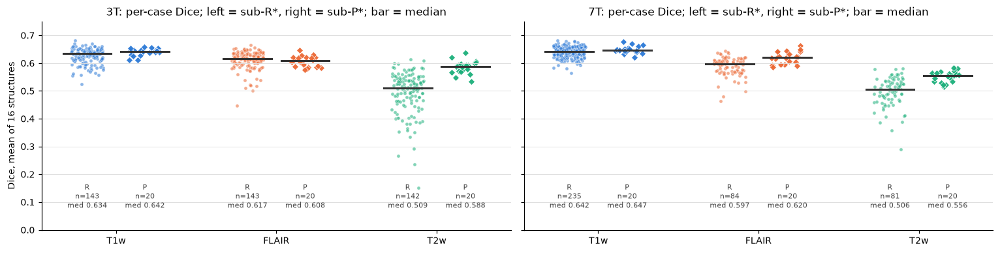

count          mean           std           min           50%  \
field              3T     7T     3T     7T     3T     7T     3T     7T     3T   
contrast group                                                                  
FLAIR    P       20.0   20.0  0.606  0.620  0.020  0.023  0.576  0.586  0.608   
         R      143.0   84.0  0.611  0.588  0.033  0.034  0.448  0.464  0.617   
T1w      P       20.0   20.0  0.640  0.648  0.013  0.013  0.612  0.620  0.642   
         R      143.0  235.0  0.626  0.640  0.028  0.019  0.523  0.564  0.634   
T2w      P       20.0   20.0  0.585  0.552  0.024  0.020  0.535  0.515  0.588   
         R      142.0   81.0  0.494  0.497  0.075  0.053  0.152  0.289  0.509   

                         max         
field              7T     3T     7T  
contrast group                       
FLAIR    P      0.620  0.646  0.664  
         R      0.597  0.666  0.644  
T1w      P      0.647  0.659  0.676  
         R      0.642  0.682  0.682  
T2w      P      0.556  0.637  0.582  
         R      0.506  0.614  0.580

In [3]:
pcm = per_case_mean.assign(group=per_case_mean.subject.str[4])
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
rng = np.random.default_rng(0)
for ax, fld in zip(axes, FIELDS):
  q = per_case_mean_all[per_case_mean_all.field == fld]
  for i, c in enumerate(CONTRASTS):
    for j, (g, mk) in enumerate((("R", "o"), ("P", "D"))):
        v = q[(q.contrast == c) & (q.group == g)].dice.values
        x = i + (j - 0.5) * 0.36 + rng.uniform(-0.1, 0.1, len(v))
        ax.scatter(x, v, s=12 if g == "R" else 22, marker=mk, color=CCOL[c], alpha=0.55 if g == "R" else 0.95,
                   edgecolor="white", linewidth=0.5)
        ax.plot([i + (j - 0.5) * 0.36 - 0.15, i + (j - 0.5) * 0.36 + 0.15], [np.median(v)] * 2, color="#333", lw=2)
        ax.text(i + (j - 0.5) * 0.36, 0.08, f"{g}\nn={len(v)}\nmed {np.median(v):.3f}", ha="center", fontsize=7.5, color="#444")
  ax.set_xticks(range(3)); ax.set_xticklabels(CONTRASTS); ax.set_ylim(0, 0.75)
  ax.set_title(f"{fld}: per-case Dice; left = sub-R*, right = sub-P*; bar = median")
  ax.grid(axis="y", color="#ddd", lw=0.6)
axes[0].set_ylabel("Dice, mean of 16 structures"); plt.tight_layout(); plt.show()
display(per_case_mean_all.groupby(["field", "contrast", "group"]).dice.describe()[["count", "mean", "std", "min", "50%", "max"]].round(3).unstack(0))

**What we see.** T1w and FLAIR are tight (most cases 0.58–0.68) and `R`/`P` behave the same. On T2w the
20 `sub-P*` cases are almost as good as on T1w (median 0.59), but the 142 `sub-R*` cases spread down to
0.15. The worst cases are shown in section 7.

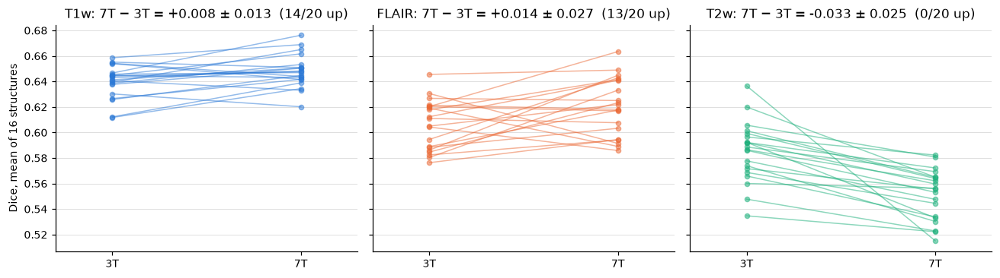

In [4]:
# same subject at 3T and 7T (sub-P* only)
w = per_case_mean_all[per_case_mean_all.group == "P"].pivot_table(index=["subject", "contrast"], columns="field", values="dice").dropna()
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for a, c in zip(axs, CONTRASTS):
    t = w.xs(c, level="contrast")
    for _, r in t.iterrows():
        a.plot([0, 1], [r["3T"], r["7T"]], color=CCOL[c], alpha=0.5, lw=1, marker="o", ms=4)
    dd = t["7T"] - t["3T"]
    a.set_title(f"{c}: 7T − 3T = {dd.mean():+.3f} ± {dd.std():.3f}  ({(dd > 0).sum()}/{len(dd)} up)")
    a.set_xticks([0, 1]); a.set_xticklabels(["3T", "7T"]); a.set_xlim(-0.3, 1.3); a.grid(axis="y", color="#ddd", lw=0.6)
axs[0].set_ylabel("Dice, mean of 16 structures"); plt.tight_layout(); plt.show()

**What we see (7T).** T1w 7T is the best and tightest condition. FLAIR 7T `R` subjects are slightly lower than
FLAIR 3T. T2w 7T has fewer extreme failures than T2w 3T, but its worst cases are again `R` subjects.
For the same `P` subjects, 7T is slightly better on T1w/FLAIR and **lower on T2w for every one of the 20 subjects**.

## 2. Per-structure Dice and volume bias

Columns: contrast × field. Left: mean Dice (darker = better). Right: median relative volume difference
(prediction − NextBrain) / NextBrain; red = nxb16 larger, blue = nxb16 smaller (clipped at ±100 %).

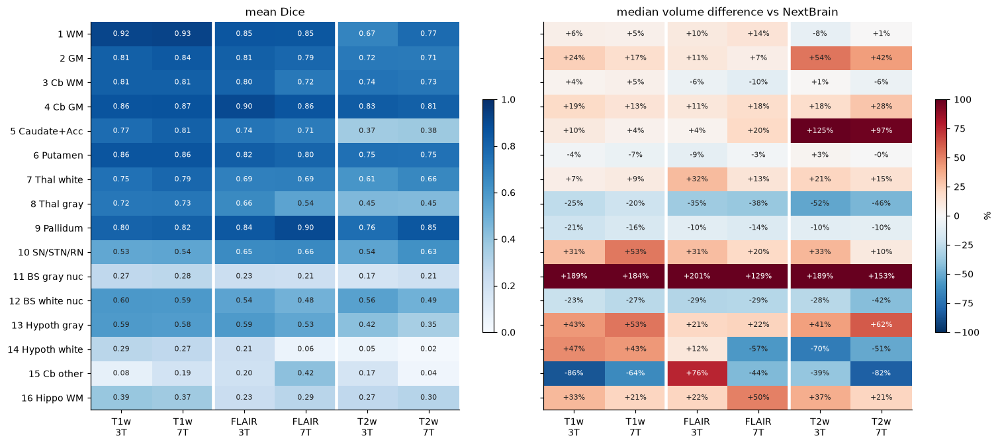

In [5]:
COLS = [(c, f) for c in CONTRASTS for f in FIELDS]
sa = summ_all[summ_all.label > 0]
dice = sa.pivot(index="label", columns=["contrast", "field"], values="dice_mean")[COLS]
vol = sa.pivot(index="label", columns=["contrast", "field"], values="rel_vol_diff_pct_median")[COLS]
ylab = [f"{l} {SHORT[l]}" for l in dice.index]
fig, axs = plt.subplots(1, 2, figsize=(14, 6.2))
im0 = axs[0].imshow(dice.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
im1 = axs[1].imshow(vol.values.clip(-100, 100), cmap="RdBu_r", norm=TwoSlopeNorm(0, -100, 100), aspect="auto")
for a, M, fmt in ((axs[0], dice.values, "{:.2f}"), (axs[1], vol.values, "{:+.0f}%")):
    a.set_xticks(range(len(COLS))); a.set_xticklabels([f"{c}\n{f}" for c, f in COLS]); a.set_yticks(range(16)); a.set_yticklabels(ylab)
    for k in (1.5, 3.5): a.axvline(k, color="white", lw=3)
    for (r, c), v in np.ndenumerate(M):
        dark = (a is axs[0] and v > 0.6) or (a is axs[1] and abs(v) > 60)
        a.text(c, r, fmt.format(v), ha="center", va="center", fontsize=7.5, color="white" if dark else "#222")
axs[1].set_yticklabels([])
axs[0].set_title("mean Dice"); axs[1].set_title("median volume difference vs NextBrain")
fig.colorbar(im0, ax=axs[0], shrink=0.6); fig.colorbar(im1, ax=axs[1], shrink=0.6, label="%")
plt.tight_layout(); plt.show()

### Where does each NextBrain structure go? (confusion matrices over all cases, 3T and 7T)

Row = NextBrain label, column = nxb16 label, each row normalized to 100 % (the diagonal is the
fraction of that NextBrain structure that nxb16 labels the same). Computed once from the
predictions and the cached mapped NextBrain segmentations, then saved to `results/confusion_<field>.npz`.

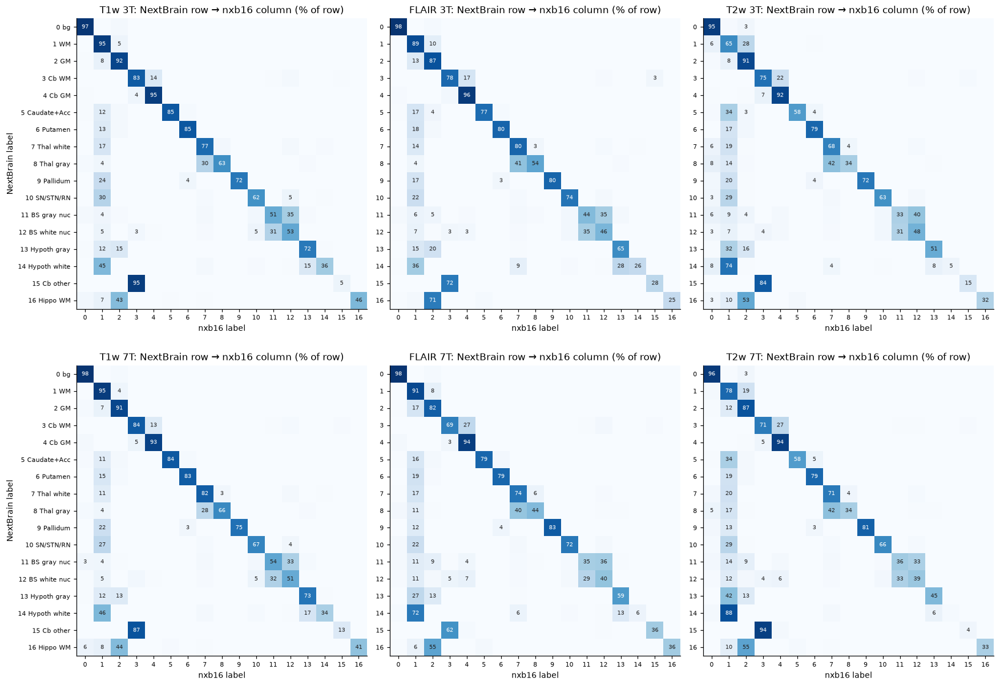

In [6]:
def conf_case(item):
    c, f, case = item
    gt = np.asanyarray(nib.load(CACHE / c / f / f"{case}.nii.gz").dataobj).astype(np.int64)
    pr = np.asanyarray(nib.load(PRED / c / f / f"{case}.nii.gz").dataobj).astype(np.int64)
    return c, np.bincount(gt.ravel() * 17 + pr.ravel(), minlength=289).reshape(17, 17)

CONF_ALL = {}
for fld in FIELDS:
    conf_file = RES / f"confusion_{fld}.npz"
    if conf_file.exists():
        CONF_ALL[fld] = dict(np.load(conf_file)); continue
    q = per_case_mean_all[per_case_mean_all.field == fld]
    conf = {c: np.zeros((17, 17), np.int64) for c in CONTRASTS}
    with Pool(48) as pool:
        for c, m in pool.imap_unordered(conf_case, [(r.contrast, fld, r.case) for r in q.itertuples()], chunksize=2):
            conf[c] += m
    np.savez(conf_file, **conf); CONF_ALL[fld] = conf
CONF = CONF_ALL[FIELD]

fig, axes = plt.subplots(2, 3, figsize=(16, 11.2))
for (fld, c), a in zip([(f, c) for f in FIELDS for c in CONTRASTS], axes.ravel()):
    M = CONF_ALL[fld][c].astype(float); M = 100 * M / M.sum(1, keepdims=True)
    a.imshow(M, cmap="Blues", vmin=0, vmax=100)
    for (r, k), v in np.ndenumerate(M):
        if v >= 3: a.text(k, r, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="white" if v > 55 else "#222")
    names = ["0 bg"] + [f"{l} {SHORT[l]}" for l in range(1, 17)]
    a.set_xticks(range(17)); a.set_xticklabels(range(17), fontsize=7); a.set_yticks(range(17))
    a.set_yticklabels(names if c == CONTRASTS[0] else range(17), fontsize=7)
    a.set_xlabel("nxb16 label"); a.set_title(f"{c} {fld}: NextBrain row → nxb16 column (% of row)")
    if c == CONTRASTS[0]: a.set_ylabel("NextBrain label")
plt.tight_layout(); plt.show()

**What we see** (each row says where the NextBrain structure ends up in nxb16; percentages quoted for 3T; 7T is very similar,
see the second row of matrices and section 9):
- Large structures are mostly on the diagonal (WM, GM, cerebellum ≥ 83–96 % on T1w/FLAIR).
- **Column 1 (WM)** takes 12–34 % of every deep gray structure (caudate, putamen, pallidum, SN/STN/RN,
  hypothalamus): nxb16 draws these nuclei with a different border to the surrounding white matter.
- **Thalamus:** 30–42 % of NextBrain *gray* thalamus becomes nxb16 *white* thalamus.
- **Brainstem:** gray and white brainstem nuclei are exchanged in roughly a third of the voxels in both directions (section 5).
- **Cerebellar other → cerebellum WM** (72–95 %), **hippocampal WM → GM** (43–71 %),
  **white hypothalamus → WM** (36–74 %): for these small structures nxb16 and NextBrain disagree on
  *where* they are, not only on their border.
- **T2w:** 28 % of NextBrain WM becomes GM. Row 0 (background) shows only a few %, but that
  is a percentage of the whole background; in mL it is the extra tissue of section 4.

## 3. Representative subject (median Dice) in the three contrasts

A `sub-P*` subject with all three contrasts whose per-case Dice is closest to each contrast's median.
Mid-axial, mid-coronal and mid-sagittal slices through the center of the brain.

In [7]:
wide = pcm.pivot_table(index="subject", columns="contrast", values="dice").dropna()
med = pcm.groupby("contrast").dice.median()
score = ((wide[CONTRASTS] - med[CONTRASTS]).abs()).sum(axis=1)
REP = score[score.index.str.startswith("sub-P")].idxmin()
print("representative subject:", REP, wide.loc[REP].round(3).to_dict(), " medians:", med.round(3).to_dict())
REP_CASES = {c: load_case(c, f"{REP}_ses-{FIELD}_{c}", raw=True) for c in CONTRASTS}

representative subject: sub-P0018 {'FLAIR': 0.604, 'T1w': 0.646, 'T2w': 0.535}  medians: {'FLAIR': 0.615, 'T1w': 0.637, 'T2w': 0.523}


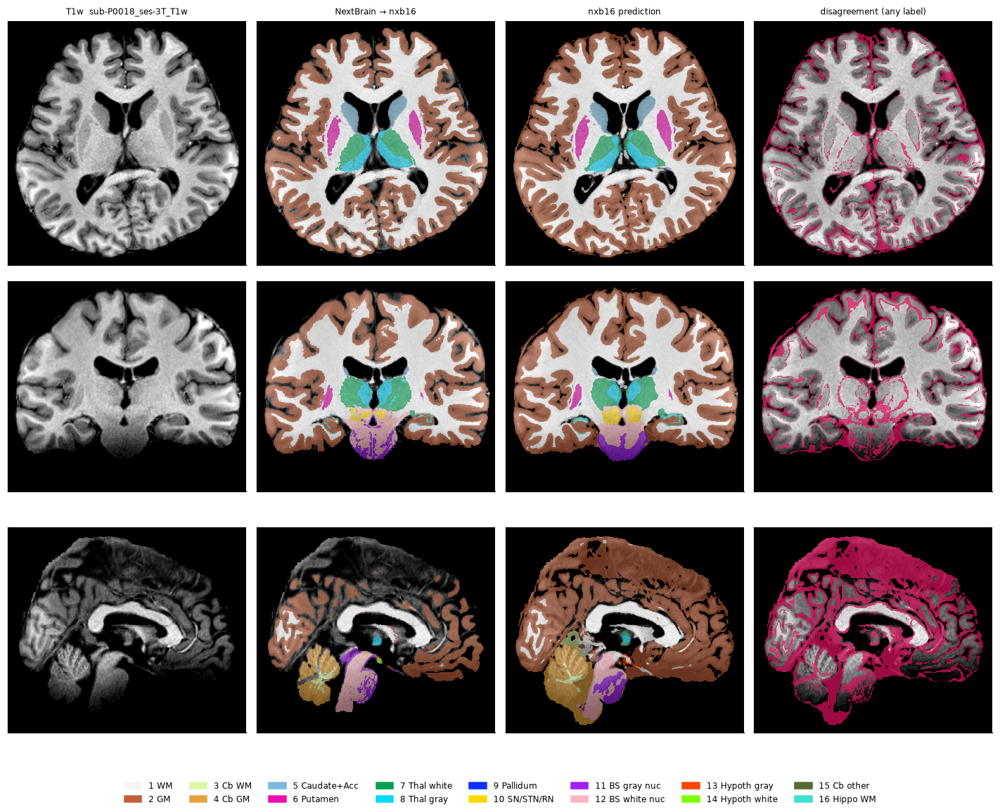

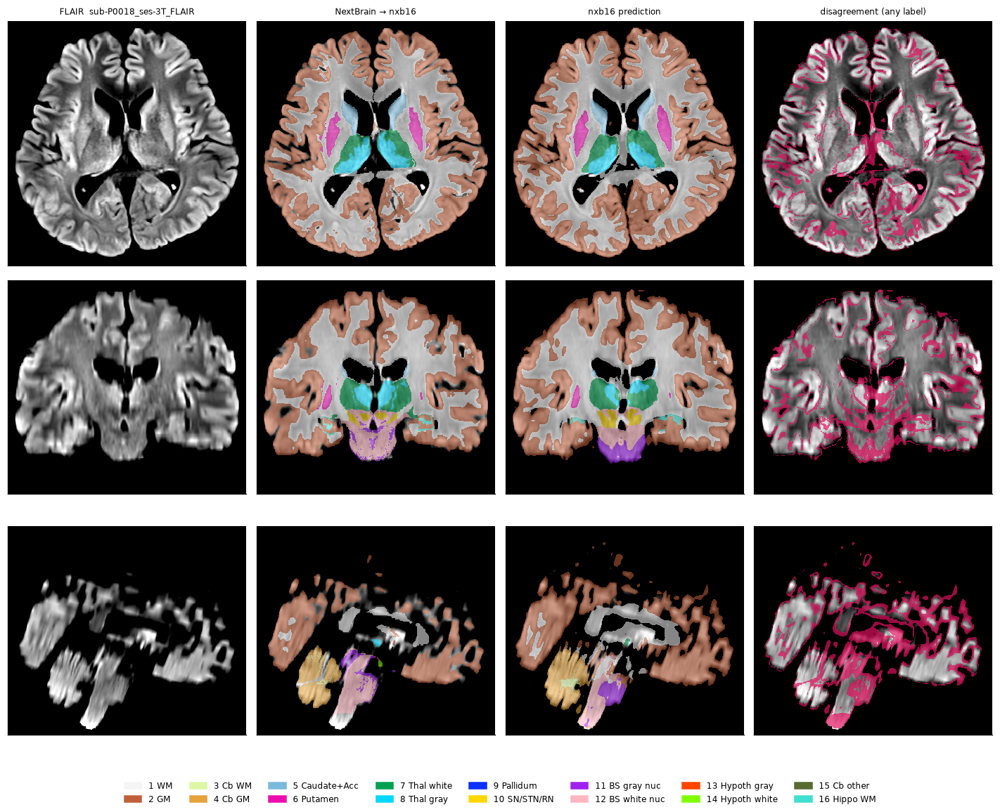

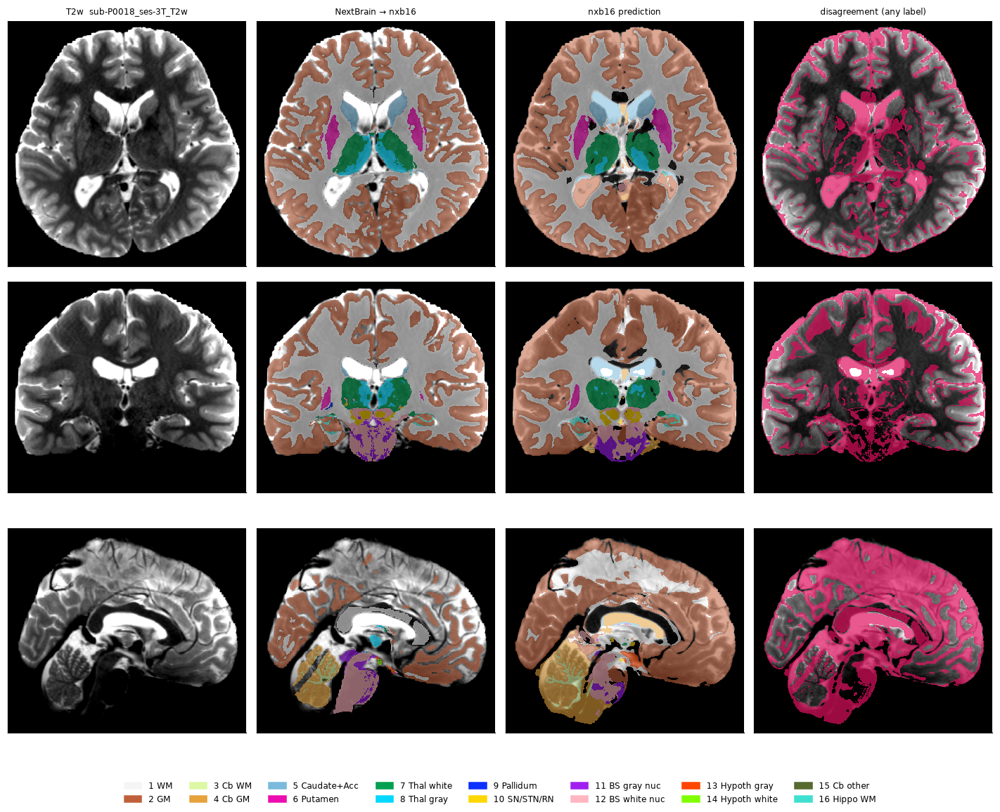

In [8]:
for c in CONTRASTS:
    d = REP_CASES[c]; cen = centroid(d["gt"] > 0)
    fig, axs = plt.subplots(3, 4, figsize=(13, 10.5))
    for row, axis in enumerate((2, 1, 0)):              # axial, coronal, sagittal
        show_row(axs[row], d, axis, cen[axis], box=crop_box(d["gt"] > 0, axis, 5, d["zooms"]), title=(row == 0))
    label_legend(fig, range(1, 17)); plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

**What we see.** On T1w/FLAIR the two segmentations look alike; the visible differences are at the
pial surface, in the brainstem and in small structures. On T2w nxb16 puts **tissue labels inside the
lateral ventricles** (caudate and gray matter colors in the ventricles), which NextBrain leaves empty.

## 4. Finding: the nxb16 brain is larger than NextBrain's (mostly gray matter)

Disagreement column: **red** = labeled as tissue by nxb16 but background by NextBrain, **blue** = the opposite.
The table says which *original* NextBrain labels sit under the red voxels (label 0 = outside the brain
in NextBrain; ventricle labels map to background in nxb16).

Sum of the 16 structures (whole labeled brain), mean over 3T cases:


,contrast,nextbrain_mL,nxb16_mL,diff_pct_mean,diff_pct_std
0,T1w,1023.5,1180.1,15.3,3.1
1,FLAIR,1075.9,1189.1,10.6,2.5
2,T2w,1053.6,1312.5,24.8,6.8


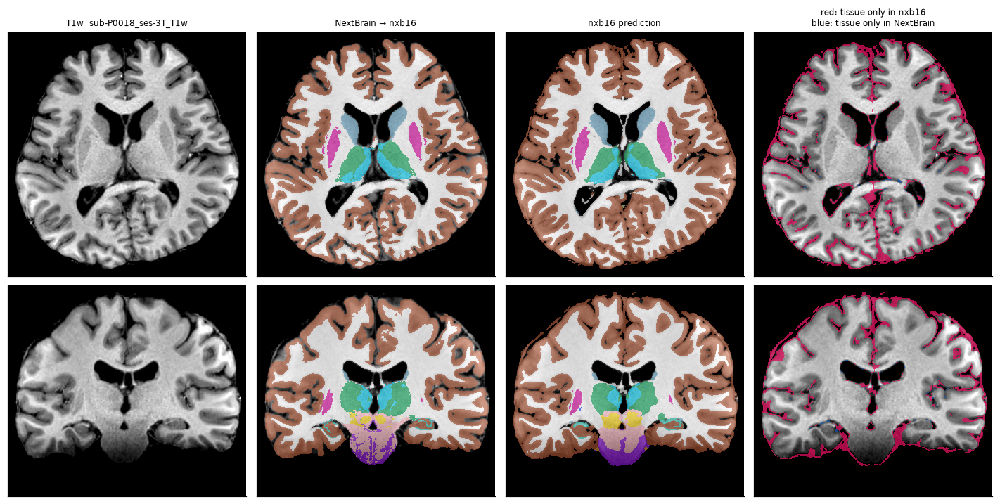

T1w: 263 mL tissue only in nxb16; original NextBrain labels there:


,nextbrain_label,name,mL,share_%
0,0,Unknown,262.81,100.0


...and the nxb16 labels it gets: {'WM': '3%', 'GM': '85%', 'Cb GM': '9%'}


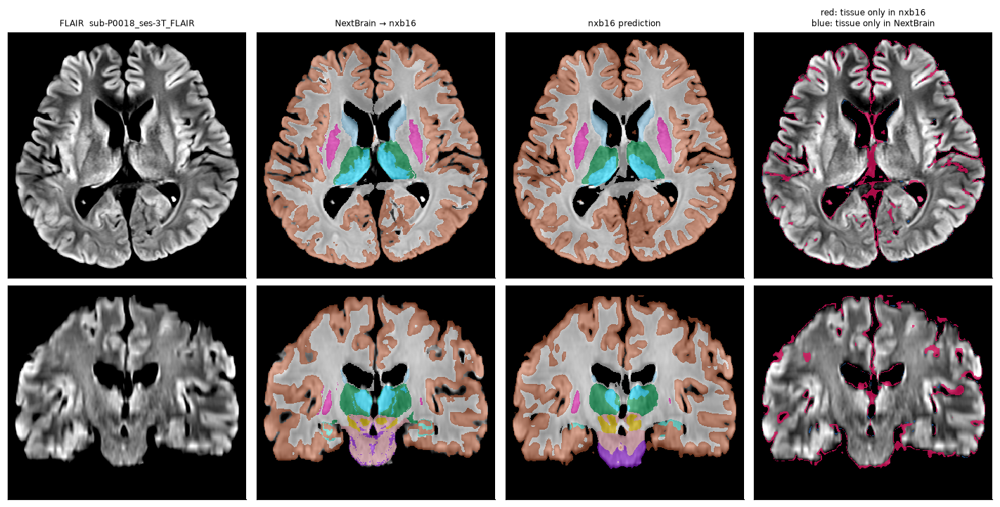

FLAIR: 124 mL tissue only in nxb16; original NextBrain labels there:


,nextbrain_label,name,mL,share_%
0,0,Unknown,124.39,100.0


...and the nxb16 labels it gets: {'WM': '10%', 'GM': '77%', 'Cb GM': '9%'}


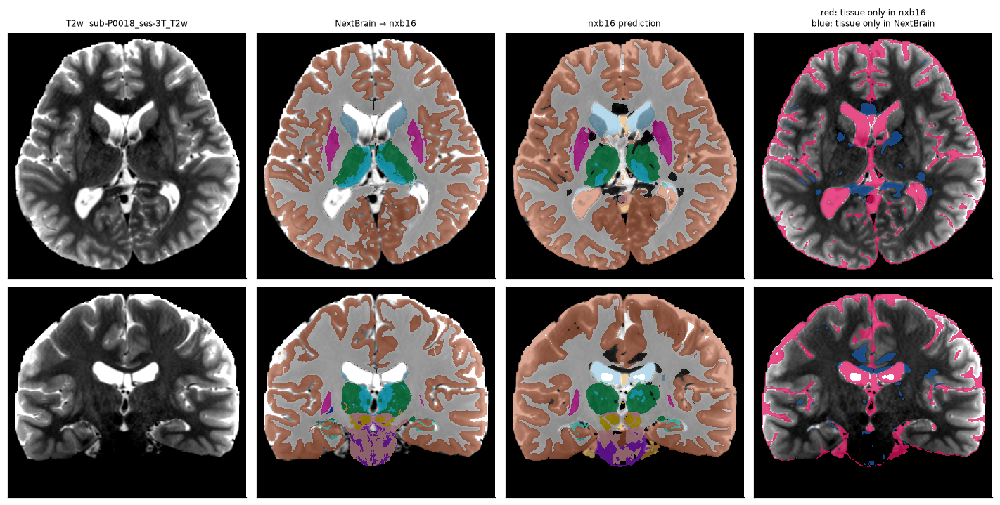

T2w: 298 mL tissue only in nxb16; original NextBrain labels there:


,nextbrain_label,name,mL,share_%
0,0,Unknown,297.87,100.0


...and the nxb16 labels it gets: {'WM': '9%', 'GM': '75%', 'Cb GM': '7%', 'Caudate+Acc': '7%'}


In [9]:
rows = []
for c in CONTRASTS:
    t = per_case[per_case.contrast == c].groupby("case")[["vol_gt_ml", "vol_pred_ml"]].sum()
    rows.append(dict(contrast=c, nextbrain_mL=t.vol_gt_ml.mean(), nxb16_mL=t.vol_pred_ml.mean(),
                     diff_pct_mean=(100 * (t.vol_pred_ml - t.vol_gt_ml) / t.vol_gt_ml).mean(),
                     diff_pct_std=(100 * (t.vol_pred_ml - t.vol_gt_ml) / t.vol_gt_ml).std()))
print("Sum of the 16 structures (whole labeled brain), mean over 3T cases:")
display(pd.DataFrame(rows).round(1))

for c in CONTRASTS:
    d = REP_CASES[c]; cen = centroid(d["gt"] > 0)
    fig, axs = plt.subplots(2, 4, figsize=(13, 6.8))
    for row, axis in enumerate((2, 1)):
        show_row(axs[row], d, axis, cen[axis], box=crop_box(d["gt"] > 0, axis, 5, d["zooms"]), err="tissue", title=(row == 0))
    plt.tight_layout(); plt.show()
    extra = (d["pred"] > 0) & (d["gt"] == 0)
    print(f"{c}: {extra.sum() * np.prod(d['zooms']) / 1000:.0f} mL tissue only in nxb16; original NextBrain labels there:")
    display(raw_breakdown(d, extra, top=6))
    print("...and the nxb16 labels it gets:",
          {SHORT[l]: f"{100 * n / extra.sum():.0f}%" for l, n in zip(*np.unique(d["pred"][extra], return_counts=True)) if n / extra.sum() > 0.02})

**What we see.**
- 100 % of the extra tissue sits on NextBrain label **0 (Unknown)**. NextBrain gives CSF no label
  (ventricles and sulci are 0), so "extra tissue" = voxels NextBrain considers CSF/outside.
- **T1w / FLAIR:** the red is a thin rim along the whole pial surface and inside sulci. nxb16 draws the cortex
  one or two voxels further out, which adds up to ~10–15 % of brain volume at 0.5 mm. The ventricles are
  correctly empty.
- **T2w:** the same rim **plus the lateral ventricles**, which nxb16 fills with tissue labels (mostly GM
  and caudate). CSF is bright on T2w and dark on T1w. A likely explanation, which I have not verified: in the nxb16 label set
  ventricles are merged into background (labels 0 and 50), so during training they always looked like
  background, and on skull-stripped T2w images background is dark while ventricles are bright.
  This also explains the T2w caudate over-segmentation (section 6) and the worst T2w cases (section 7).

## 5. Finding: gray vs white brainstem nuclei (and thalamus) split differently

Crops centered on the brainstem (labels 11 + 12) and on the thalamus (7 + 8) of the representative subject.
The first table lists the original NextBrain labels of the voxels that NextBrain maps to *white
brainstem nuclei* (12) but nxb16 calls *gray brainstem nuclei* (11).

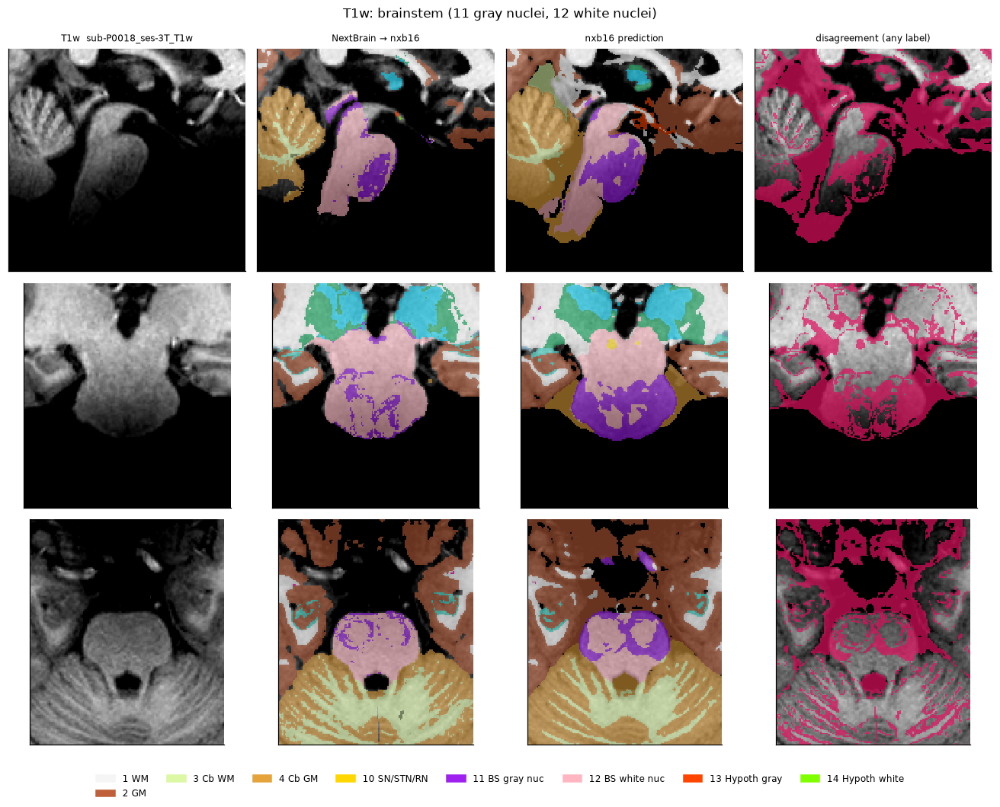

T1w: NextBrain 12 → nxb16 11: 4.99 mL; original NextBrain labels:


,nextbrain_label,name,mL,share_%
0,580,pons,3.66,73.4
1,611,white_matter_of_hindbrain,1.20,24.0
2,384,midbrain_(mesencephalon),0.11,2.3
3,697,inferior_cerebellar_peduncle,0.01,0.2
4,662,myelencephalon_(medulla_oblongata),0.00,0.1


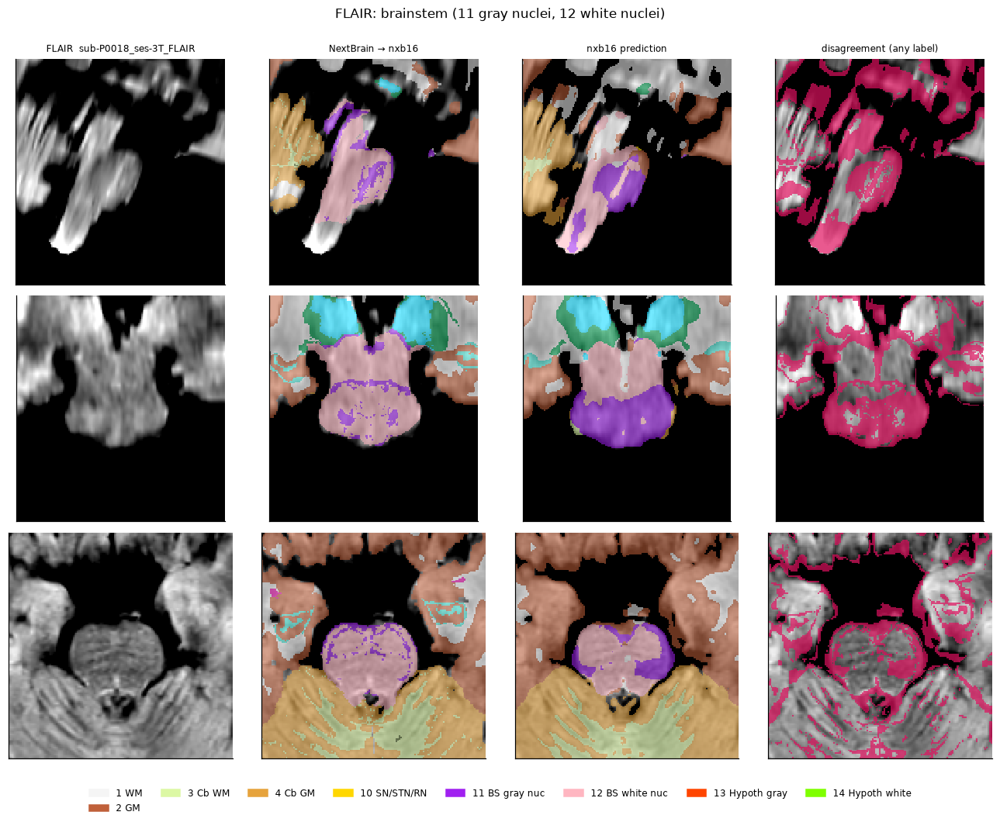

FLAIR: NextBrain 12 → nxb16 11: 6.32 mL; original NextBrain labels:


,nextbrain_label,name,mL,share_%
0,580,pons,5.55,87.8
1,611,white_matter_of_hindbrain,0.46,7.2
2,384,midbrain_(mesencephalon),0.29,4.5
3,662,myelencephalon_(medulla_oblongata),0.03,0.5


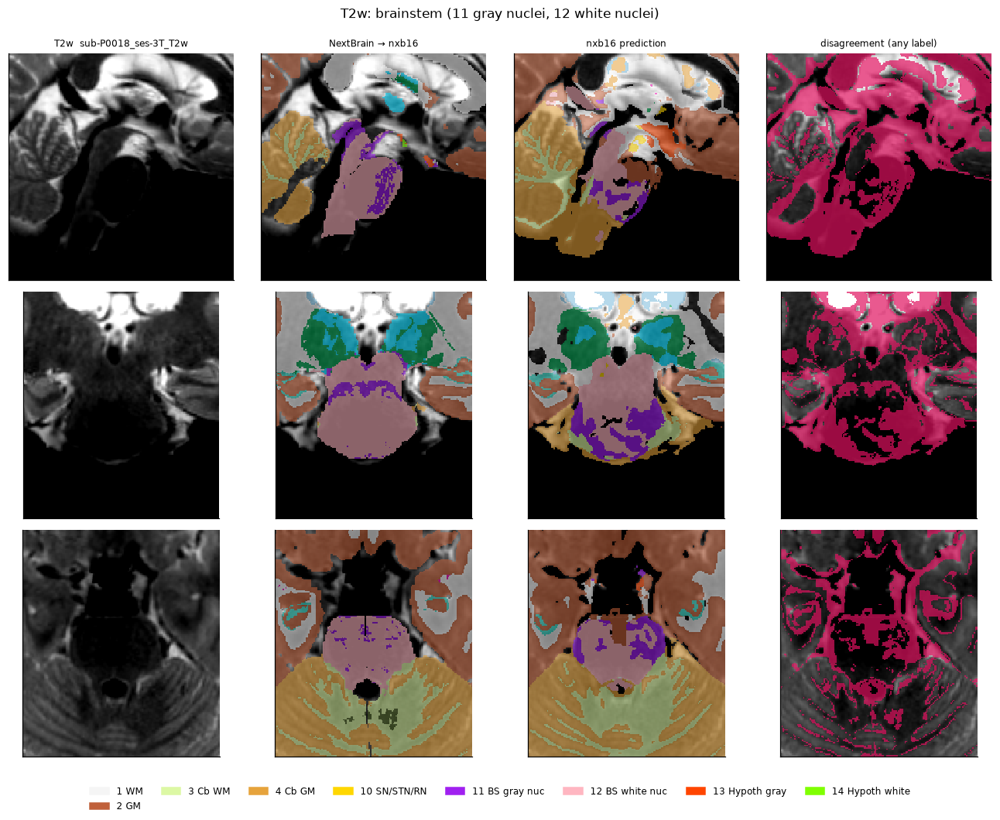

T2w: NextBrain 12 → nxb16 11: 4.80 mL; original NextBrain labels:


,nextbrain_label,name,mL,share_%
0,580,pons,3.79,78.8
1,611,white_matter_of_hindbrain,0.88,18.2
2,384,midbrain_(mesencephalon),0.14,2.9
3,662,myelencephalon_(medulla_oblongata),0.00,0.1


In [10]:
def zoom_fig(d, labels, title, margin=12):
    m = np.isin(d["gt"], labels) | np.isin(d["pred"], labels); cen = centroid(np.isin(d["gt"], labels))
    fig, axs = plt.subplots(3, 4, figsize=(12, 9.5))
    for row, axis in enumerate((0, 1, 2)):          # sagittal, coronal, axial
        show_row(axs[row], d, axis, cen[axis], box=crop_box(m, axis, margin, d["zooms"]), title=(row == 0))
    fig.suptitle(title, y=1.0); label_legend(fig, sorted(set(labels) | {1, 2, 3, 4, 10, 13, 14})); plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

for c in CONTRASTS:
    d = REP_CASES[c]
    zoom_fig(d, [11, 12], f"{c}: brainstem (11 gray nuclei, 12 white nuclei)")
    sel = (d["gt"] == 12) & (d["pred"] == 11)
    print(f"{c}: NextBrain 12 → nxb16 11: {sel.sum() * np.prod(d['zooms']) / 1000:.2f} mL; original NextBrain labels:")
    display(raw_breakdown(d, sel, top=8))

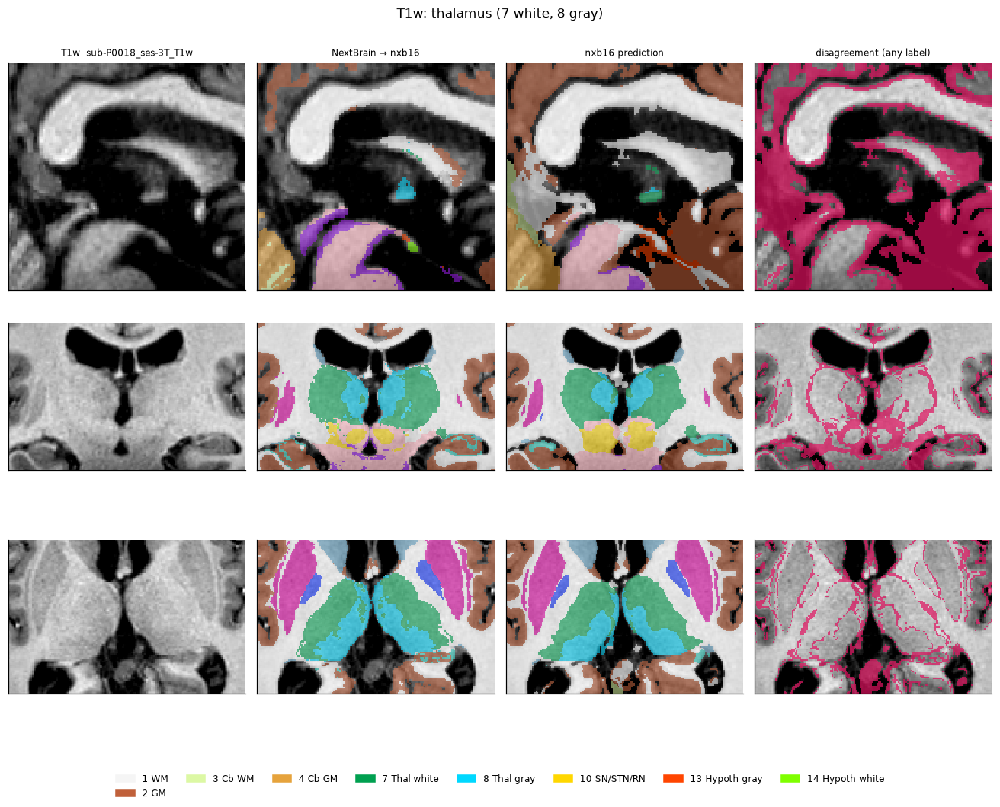

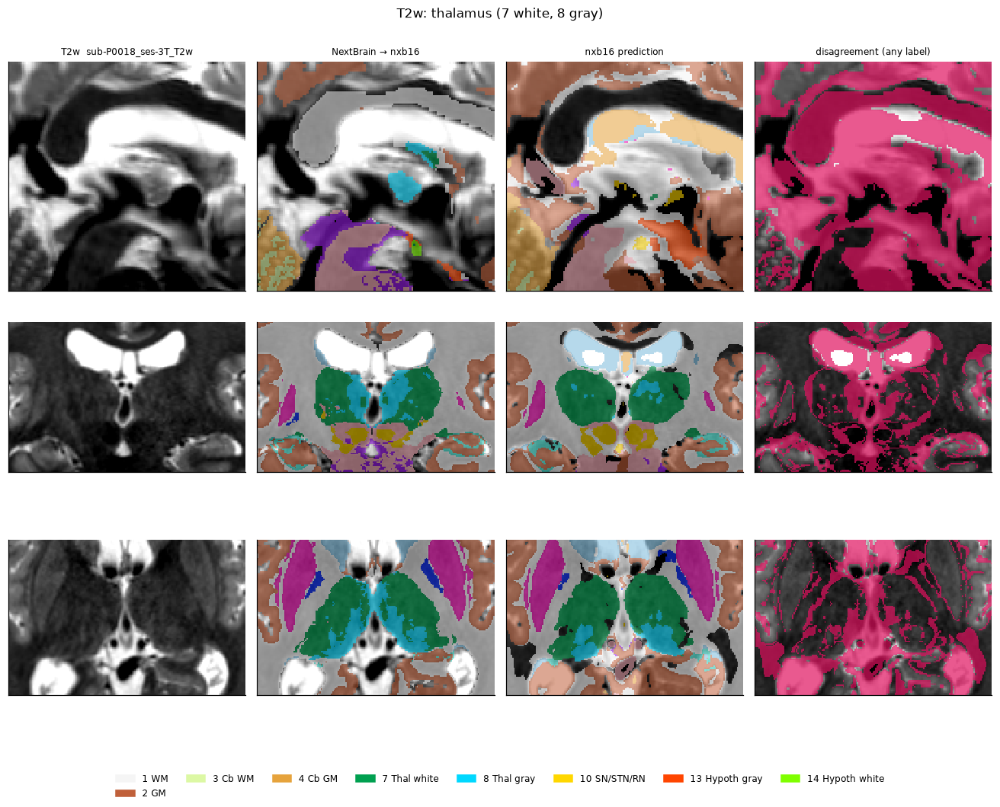

In [11]:
for c in ["T1w", "T2w"]:
    zoom_fig(REP_CASES[c], [7, 8], f"{c}: thalamus (7 white, 8 gray)")

**What we see.** The disagreement is the **ventral pons (basis pontis)**. NextBrain labels it mostly
`pons` (580, mapped to *white* brainstem nuclei) with scattered `pontine_nucleus` (414, *gray*). nxb16
labels the whole basis pontis as *gray* brainstem nuclei. About 3.5–5.5 mL of NextBrain `pons` per subject
goes to gray in every contrast. This depends on how the pons is defined (the basis pontis really is
pontine nuclei intermixed with transverse fibers) and has nothing to do with image contrast. To decide which one is right, check how
basis pontis is labeled in the training label maps, and whether `pons` (580) belongs in the white group of
`nextbrain_to_nxb16.yaml`.

Thalamus: the gray/white thalamus border differs (gray thalamus is under-segmented by 25–50 %), but
the thalamus as a whole matches well.

## 6. Finding: caudate + accumbens over-segmented on T2w (+125 %)

Same subject, T1w vs T2w, crop around the caudate (label 5). On T2w the ventricles are bright; the
table lists the original NextBrain labels of voxels that nxb16 calls caudate but NextBrain does not.
For contrast, the next cell shows a T2w case with a large caudate over-segmentation.

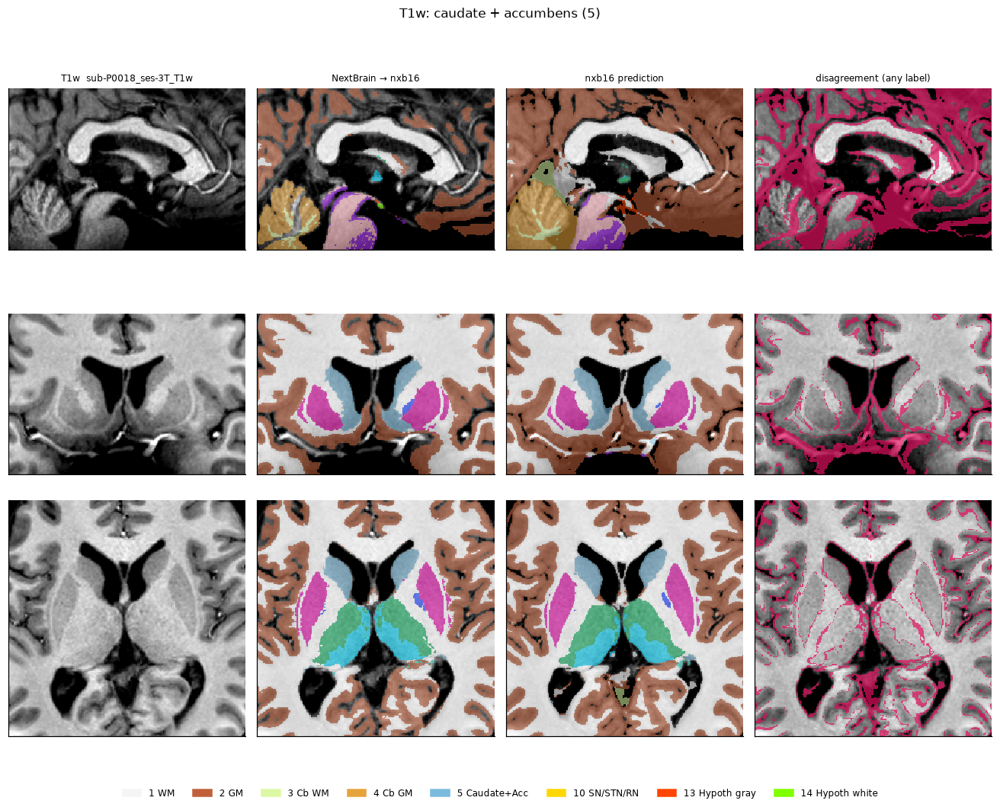

T1w: nxb16 caudate outside NextBrain caudate: 1.26 mL; original NextBrain labels:


,nextbrain_label,name,mL,share_%
0,0,Unknown,0.79,62.9
1,7,white_matter_of_forebrain,0.35,27.9
2,79,putamen,0.06,4.6
3,117,bed_nucleus_of_stria_terminalis,0.02,1.6
4,354,alveus,0.01,1.2
5,2014,ctx-medialorbitofrontal,0.00,0.4


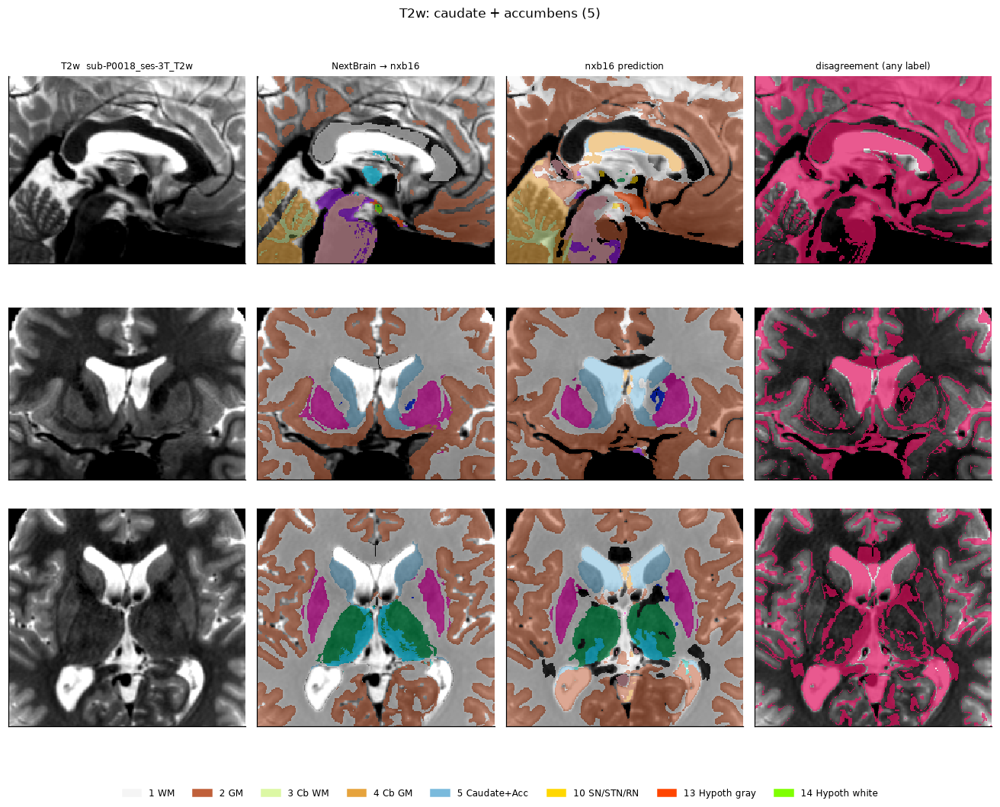

T2w: nxb16 caudate outside NextBrain caudate: 21.22 mL; original NextBrain labels:


,nextbrain_label,name,mL,share_%
0,0,Unknown,20.46,96.4
1,7,white_matter_of_forebrain,0.41,1.9
2,79,putamen,0.16,0.8
3,354,alveus,0.05,0.2
4,343,stratum_lacunosum-moleculare_of_rostral_ca1,0.03,0.1
5,420,stratum_pyramidale_of_rostral_ca3,0.02,0.1


In [12]:
for c in ["T1w", "T2w"]:
    d = REP_CASES[c]
    zoom_fig(d, [5], f"{c}: caudate + accumbens (5)", margin=15)
    sel = (d["pred"] == 5) & (d["gt"] != 5)
    print(f"{c}: nxb16 caudate outside NextBrain caudate: {sel.sum() * np.prod(d['zooms']) / 1000:.2f} mL; original NextBrain labels:")
    display(raw_breakdown(d, sel, top=6))

{'dice': 0.36, 'vol_gt_ml': 7.12, 'vol_pred_ml': 21.1, 'rel_vol_diff_pct': 196.5}


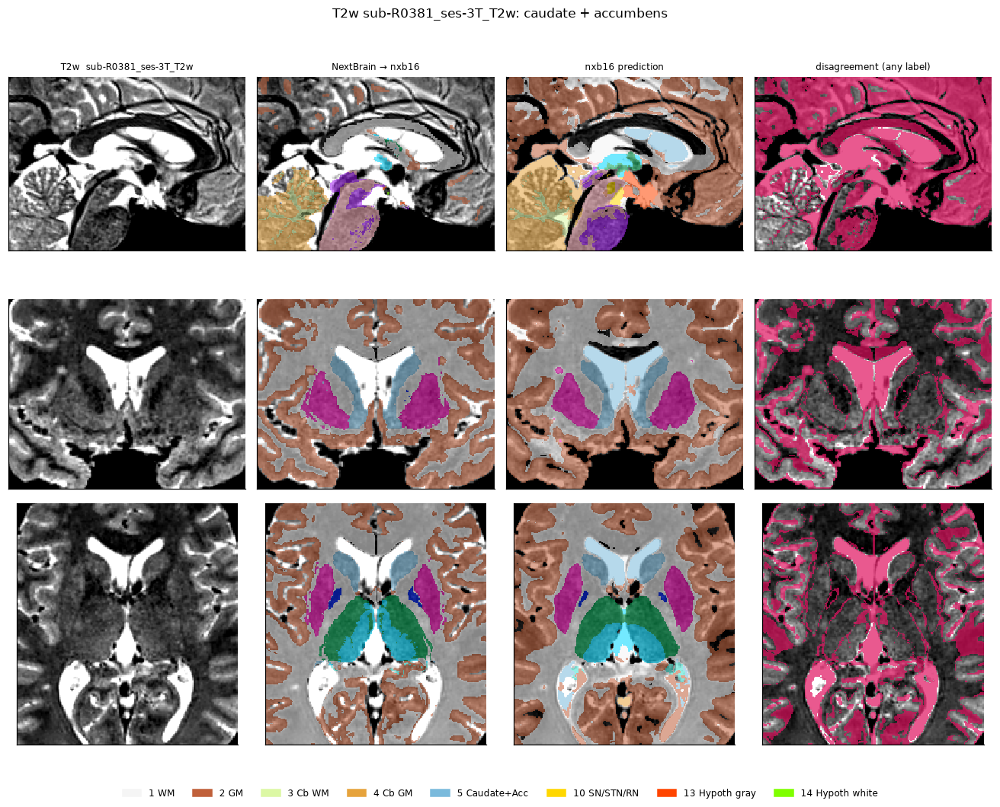

,nextbrain_label,name,mL,share_%
0,0,Unknown,15.62,97.7
1,7,white_matter_of_forebrain,0.26,1.6
2,354,alveus,0.02,0.1
3,79,putamen,0.02,0.1
4,220,anteroventral_nucleus_of_thalamus,0.02,0.1
5,432,pyramidal_cells_of_rostral_ca4,0.01,0.0


In [13]:
cau = per_case[(per_case.contrast == "T2w") & (per_case.label == 5)].sort_values("rel_vol_diff_pct")
CAU_CASE = cau.iloc[int(0.9 * len(cau))].case          # 90th percentile of over-segmentation
print(cau.set_index("case").loc[CAU_CASE, ["dice", "vol_gt_ml", "vol_pred_ml", "rel_vol_diff_pct"]].round(2).to_dict())
d = load_case("T2w", CAU_CASE, raw=True)
zoom_fig(d, [5], f"T2w {CAU_CASE}: caudate + accumbens", margin=15)
display(raw_breakdown(d, (d["pred"] == 5) & (d["gt"] != 5), top=6))

**What we see.** On T1w the nxb16 caudate overlaps NextBrain's (only ~1 mL extra). On T2w ~21 mL extra
(the caudate more than triples), and 96 % of it is NextBrain label 0 inside the **lateral ventricles**.
In the coronal and axial crops the bright ventricle lumen is painted with the caudate label. The
T2w caudate "over-segmentation" is therefore a ventricle problem, not a caudate border problem.

## 7. Finding: the worst T2w cases (`sub-R*`)

The three worst T2w cases next to the same subject's T1w, mid-axial and mid-coronal. Compare the
image appearance (contrast, resolution, field of view) with the representative `sub-P*` T2w above.

,case,dice,abs_rel_vol_diff_pct
786,sub-R0411_ses-3T_T2w,0.152,73.461
721,sub-R0345_ses-3T_T2w,0.235,57.894
746,sub-R0370_ses-3T_T2w,0.268,81.510


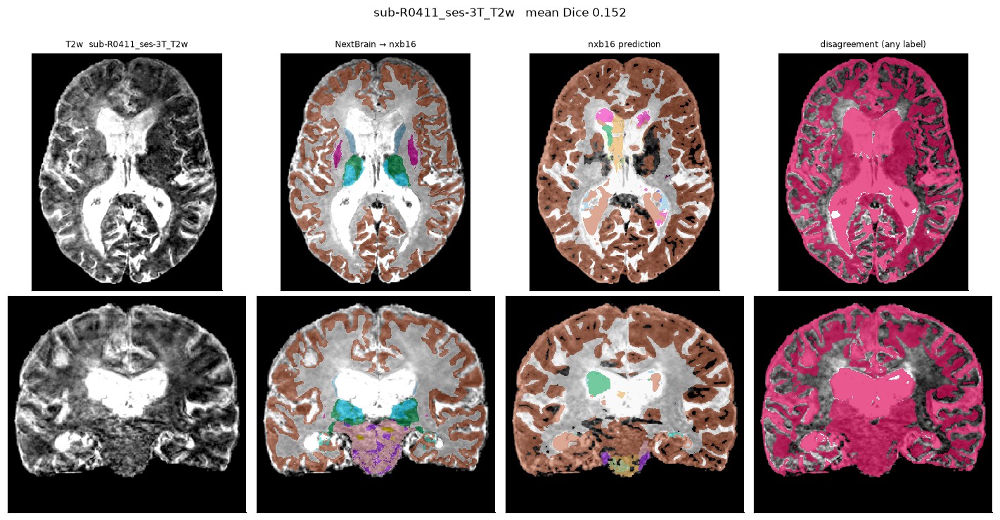

T2w voxel size [0.5 0.5 0.5] shape (364, 436, 364)


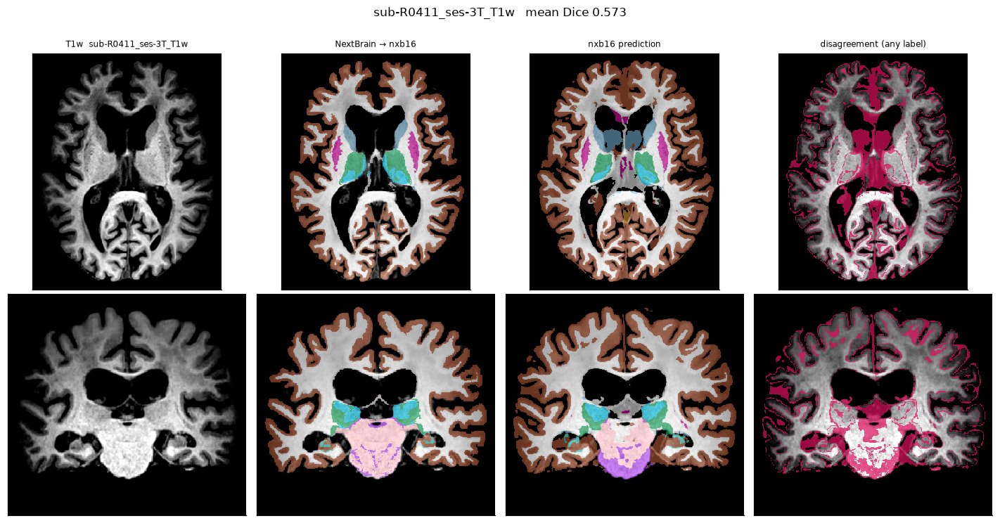

T1w voxel size [0.5 0.5 0.5] shape (364, 436, 364)


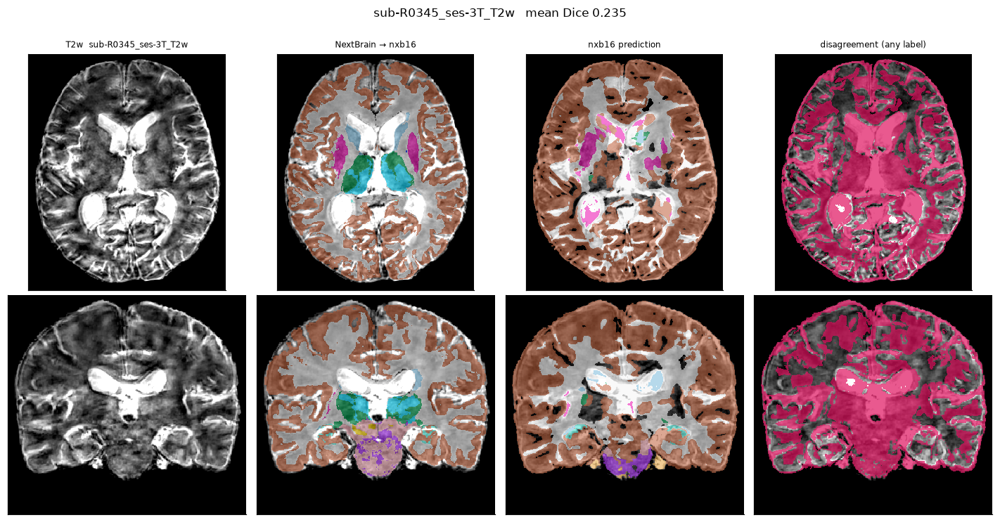

T2w voxel size [0.5 0.5 0.5] shape (364, 436, 364)


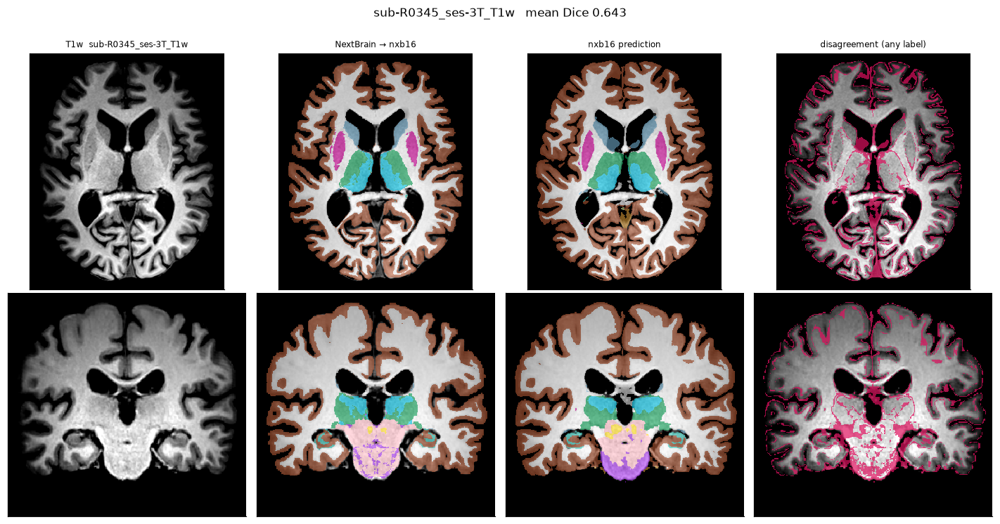

T1w voxel size [0.5 0.5 0.5] shape (364, 436, 364)


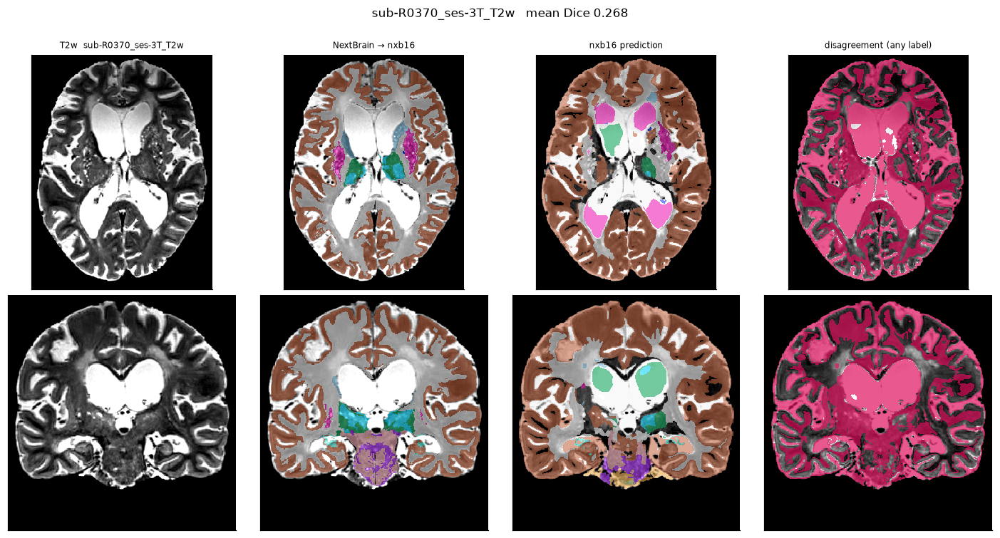

T2w voxel size [0.5 0.5 0.5] shape (364, 436, 364)


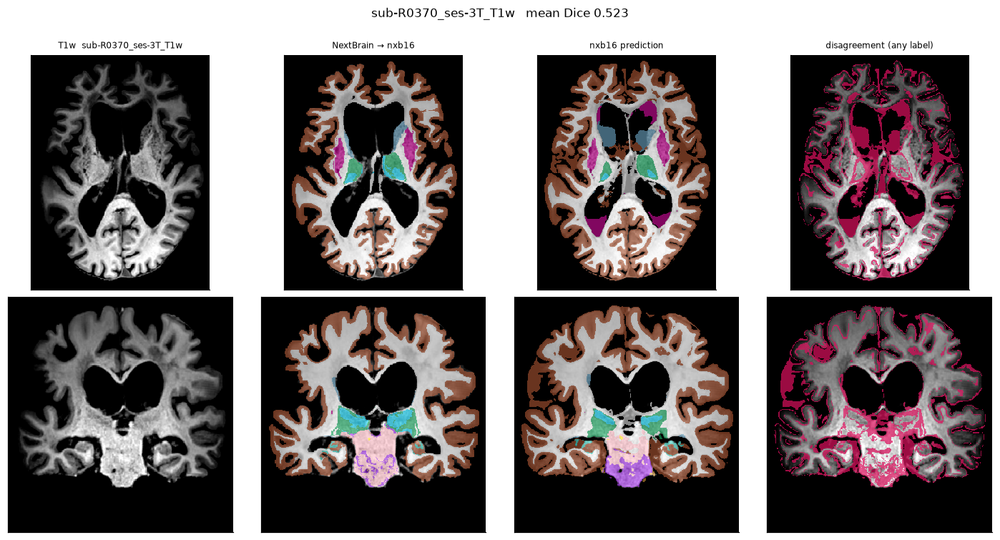

T1w voxel size [0.5 0.5 0.5] shape (364, 436, 364)


In [14]:
worst = pcm[pcm.contrast == "T2w"].nsmallest(3, "dice")
display(worst[["case", "dice", "abs_rel_vol_diff_pct"]].round(3))
for case in worst.case:
    sub = case.split("_")[0]
    for c in ["T2w", "T1w"]:
        cc = f"{sub}_ses-{FIELD}_{c}"
        if not (PRED / c / FIELD / f"{cc}.nii.gz").exists(): continue
        d = load_case(c, cc); cen = centroid(d["gt"] > 0)
        dc = pcm[(pcm.contrast == c) & (pcm.case == cc)].dice.iloc[0]
        fig, axs = plt.subplots(2, 4, figsize=(13, 6.8))
        for row, axis in enumerate((2, 1)):
            show_row(axs[row], d, axis, cen[axis], box=crop_box(d["gt"] > 0, axis, 5, d["zooms"]), title=(row == 0))
        fig.suptitle(f"{cc}   mean Dice {dc:.3f}", y=1.0); plt.tight_layout(); plt.show()
        print(c, "voxel size", np.round(d["zooms"], 2), "shape", d["img"].shape)

**What we see.** The worst T2w cases (`sub-R0411`, `sub-R0345`, `sub-R0370`) have **large ventricles**
and lots of bright CSF / white-matter hyperintensity on T2w. nxb16 fills the enlarged ventricles with tissue labels
(putamen, thalamus, GM colors) and the segmentation breaks down around them. The same subjects on T1w
are segmented normally. So the `R` vs `P` gap on T2w comes from the T2w ventricle problem, which gets
worse in subjects with more CSF. It is not a general failure on these subjects.

## 8. Finding: very small structures (hypothalamus, cerebellar other, hippocampal WM)

Dice vs NextBrain volume per case and structure: below ~2 mL the Dice values spread out and drop,
regardless of contrast.

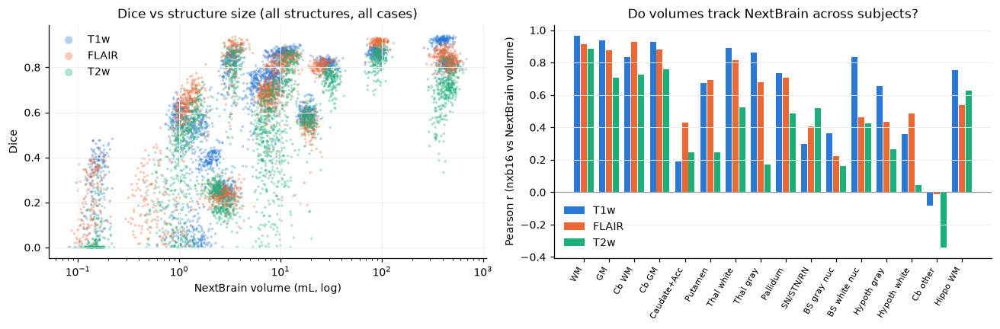

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for c in CONTRASTS:
    t = per_case[per_case.contrast == c]
    axs[0].scatter(t.vol_gt_ml, t.dice, s=5, alpha=0.35, color=CCOL[c], label=c, edgecolor="none")
axs[0].set_xscale("log"); axs[0].set_xlabel("NextBrain volume (mL, log)"); axs[0].set_ylabel("Dice")
axs[0].legend(frameon=False, markerscale=3); axs[0].set_title("Dice vs structure size (all structures, all cases)")
axs[0].grid(color="#eee", lw=0.6)
r = summ[summ.label > 0].pivot(index="label", columns="contrast", values="vol_pearson_r")[CONTRASTS]
x = np.arange(16); w = 0.27
for i, c in enumerate(CONTRASTS):
    axs[1].bar(x + (i - 1) * w, r[c].values, w * 0.9, color=CCOL[c], label=c)
axs[1].set_xticks(x); axs[1].set_xticklabels([SHORT[l] for l in r.index], rotation=60, ha="right", fontsize=7.5)
axs[1].axhline(0, color="#999", lw=0.8); axs[1].set_ylabel("Pearson r (nxb16 vs NextBrain volume)")
axs[1].set_title("Do volumes track NextBrain across subjects?"); axs[1].legend(frameon=False)
axs[1].grid(axis="y", color="#eee", lw=0.6)
plt.tight_layout(); plt.show()

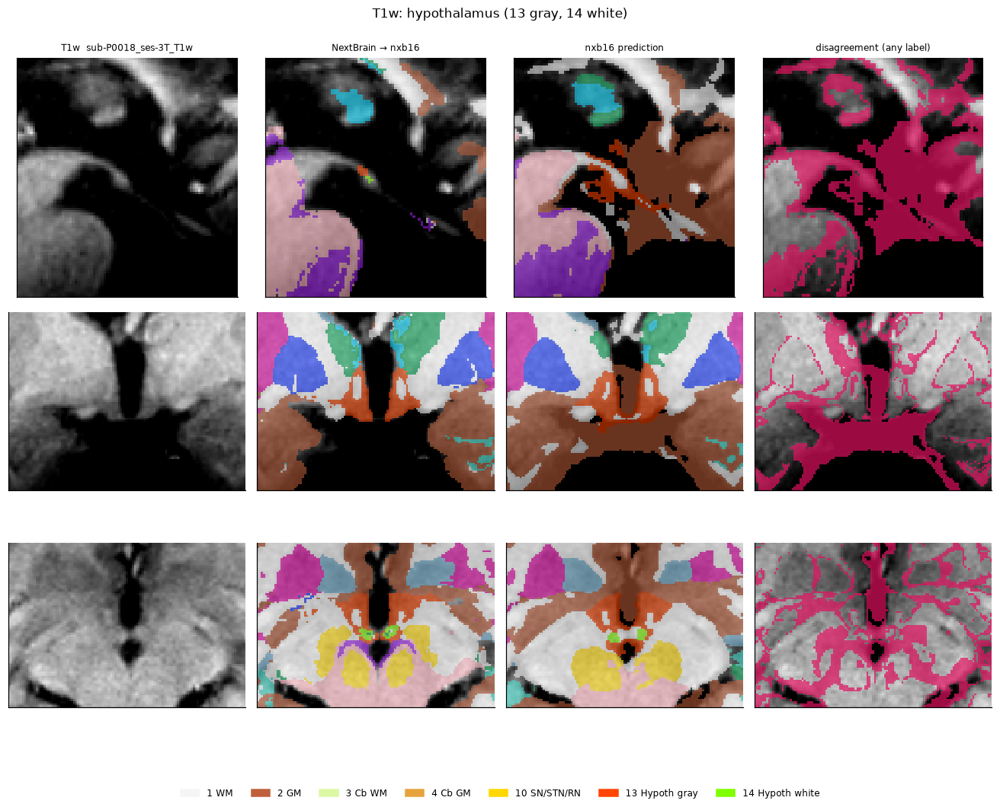

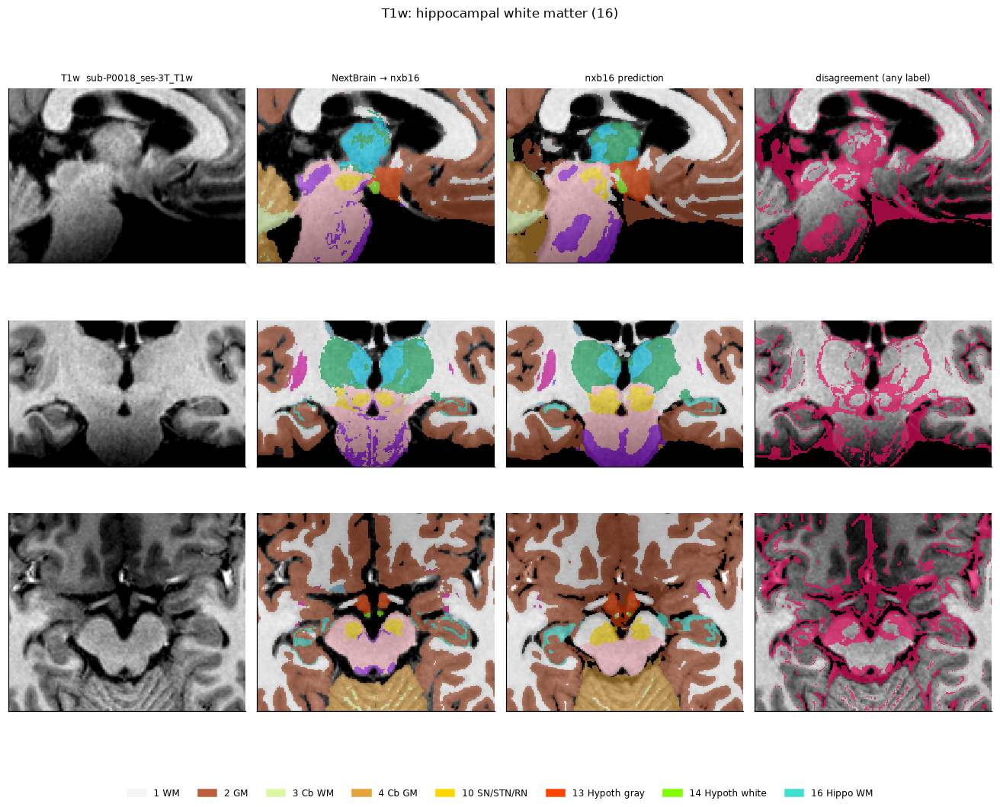

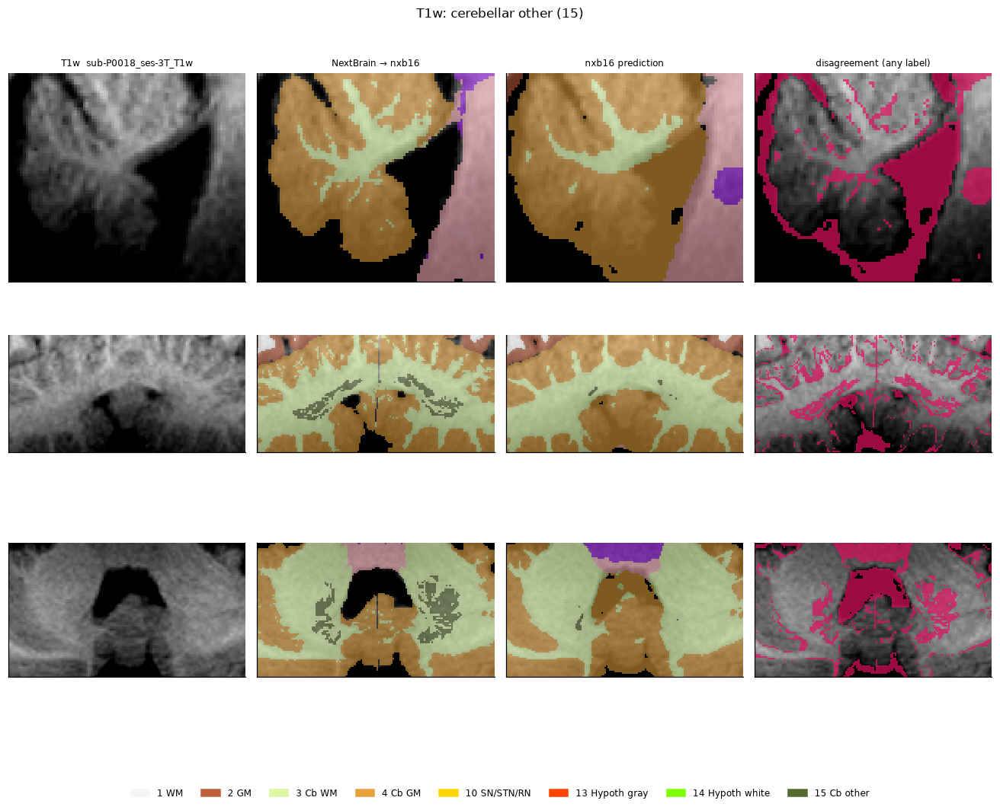

In [16]:
d = REP_CASES["T1w"]
zoom_fig(d, [13, 14], "T1w: hypothalamus (13 gray, 14 white)", margin=10)
zoom_fig(d, [16], "T1w: hippocampal white matter (16)", margin=10)
zoom_fig(d, [15], "T1w: cerebellar other (15)", margin=10)

**What we see.** Below ~2 mL Dice spreads between 0 and 0.7, and the per-subject volumes barely track
NextBrain (Pearson r ≤ 0.5; cerebellar other r < 0). NextBrain's *cerebellar other* is scattered small
pieces inside the cerebellar white matter, which nxb16 labels as cerebellar WM. nxb16 instead puts its
label 15 in a compact medial region. Hippocampal WM and white hypothalamus are thin bands that nxb16
mostly assigns to the neighboring GM/WM. For these structures Dice mostly reflects how each method
defines them. Leave them out of the headline mean or report them separately.

## 9. 7T: are the same patterns there?

A `sub-P*` subject at 7T (closest to the 7T medians in the three contrasts), with the extra/missing
tissue map, the brainstem and the caudate, and then the worst 7T T2w cases.

7T representative subject: sub-P0018 {'FLAIR': 0.586, 'T1w': 0.647, 'T2w': 0.522}  medians: {'FLAIR': 0.6, 'T1w': 0.643, 'T2w': 0.519}


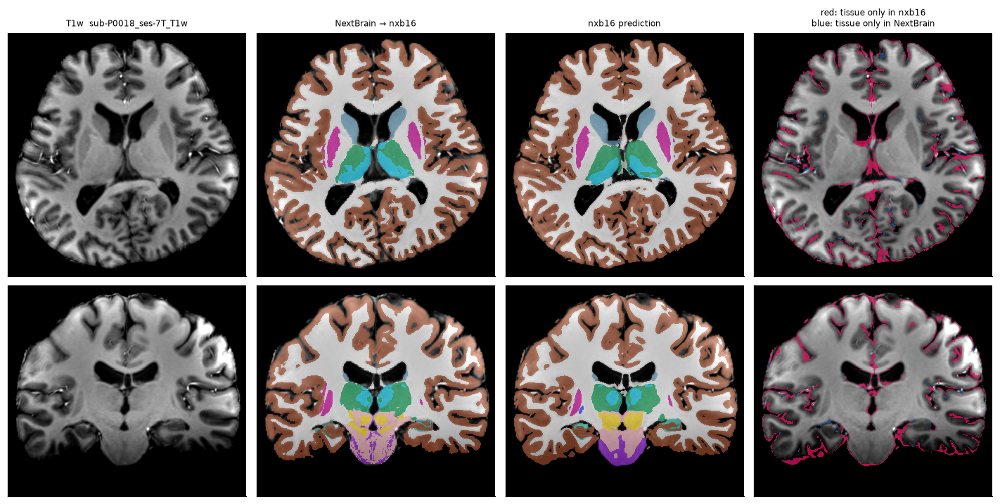

T1w 7T: 162 mL tissue only in nxb16; original NextBrain labels there:


,nextbrain_label,name,mL,share_%
0,0,Unknown,161.81,100.0


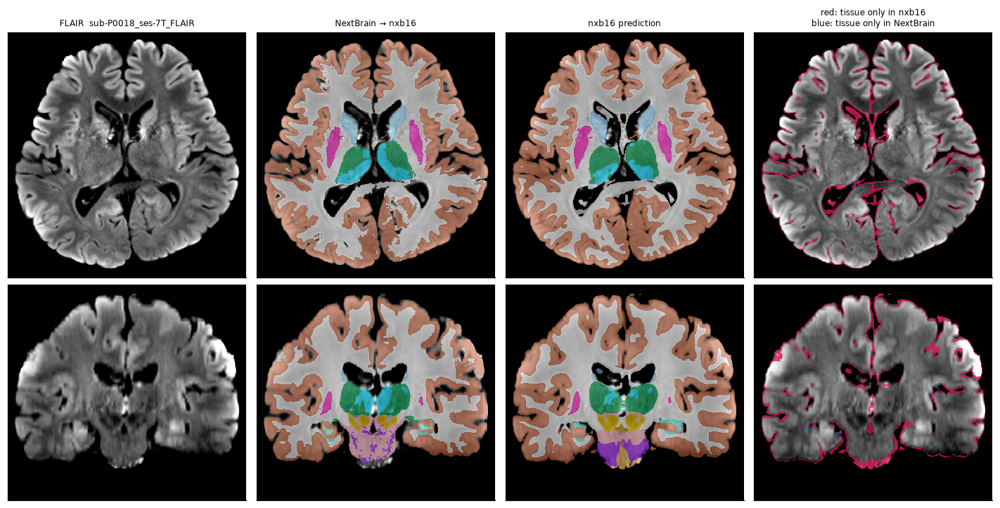

FLAIR 7T: 145 mL tissue only in nxb16; original NextBrain labels there:


,nextbrain_label,name,mL,share_%
0,0,Unknown,145.13,100.0


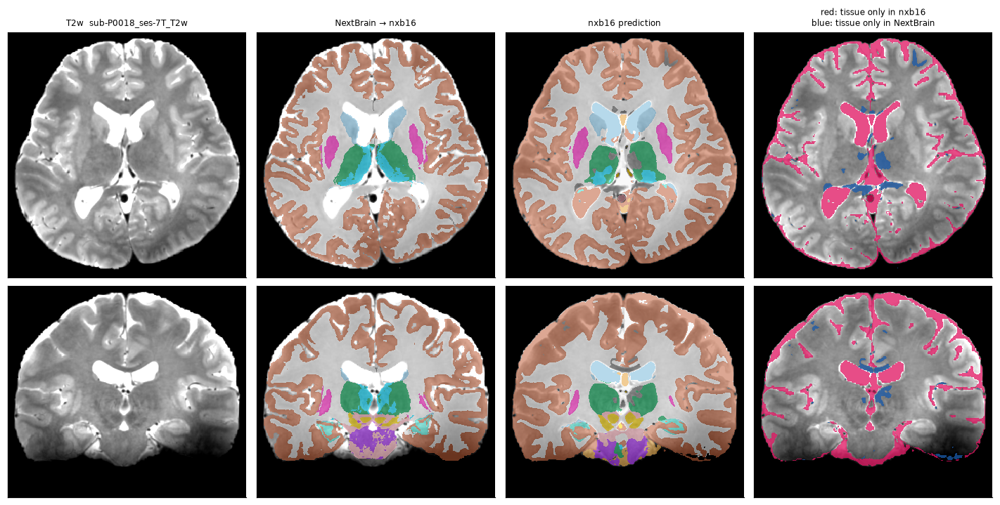

T2w 7T: 300 mL tissue only in nxb16; original NextBrain labels there:


,nextbrain_label,name,mL,share_%
0,0,Unknown,299.64,100.0


In [17]:
q7 = per_case_mean_all[per_case_mean_all.field == "7T"]
wide7 = q7.pivot_table(index="subject", columns="contrast", values="dice").dropna()
med7 = q7.groupby("contrast").dice.median()
score7 = (wide7[CONTRASTS] - med7[CONTRASTS]).abs().sum(axis=1)
REP7 = score7[score7.index.str.startswith("sub-P")].idxmin()
print("7T representative subject:", REP7, wide7.loc[REP7].round(3).to_dict(), " medians:", med7.round(3).to_dict())
REP7_CASES = {c: load_case(c, f"{REP7}_ses-7T_{c}", raw=True) for c in CONTRASTS}
for c in CONTRASTS:
    d = REP7_CASES[c]; cen = centroid(d["gt"] > 0)
    fig, axs = plt.subplots(2, 4, figsize=(13, 6.8))
    for row, axis in enumerate((2, 1)):
        show_row(axs[row], d, axis, cen[axis], box=crop_box(d["gt"] > 0, axis, 5, d["zooms"]), err="tissue", title=(row == 0))
    plt.tight_layout(); plt.show()
    extra = (d["pred"] > 0) & (d["gt"] == 0)
    print(f"{c} 7T: {extra.sum() * np.prod(d['zooms']) / 1000:.0f} mL tissue only in nxb16; original NextBrain labels there:")
    display(raw_breakdown(d, extra, top=4))

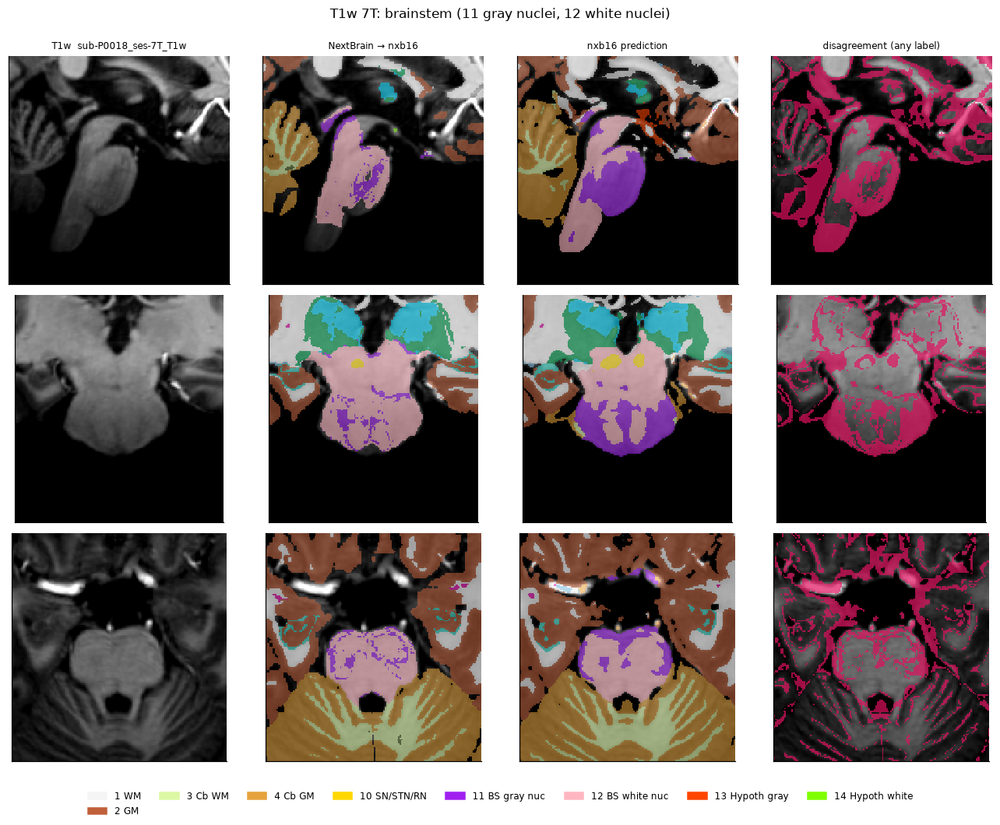

T1w 7T: NextBrain 12 → nxb16 11: 5.44 mL


,nextbrain_label,name,mL,share_%
0,580,pons,4.05,74.4
1,611,white_matter_of_hindbrain,1.00,18.4
2,384,midbrain_(mesencephalon),0.27,5.0
3,662,myelencephalon_(medulla_oblongata),0.11,2.0


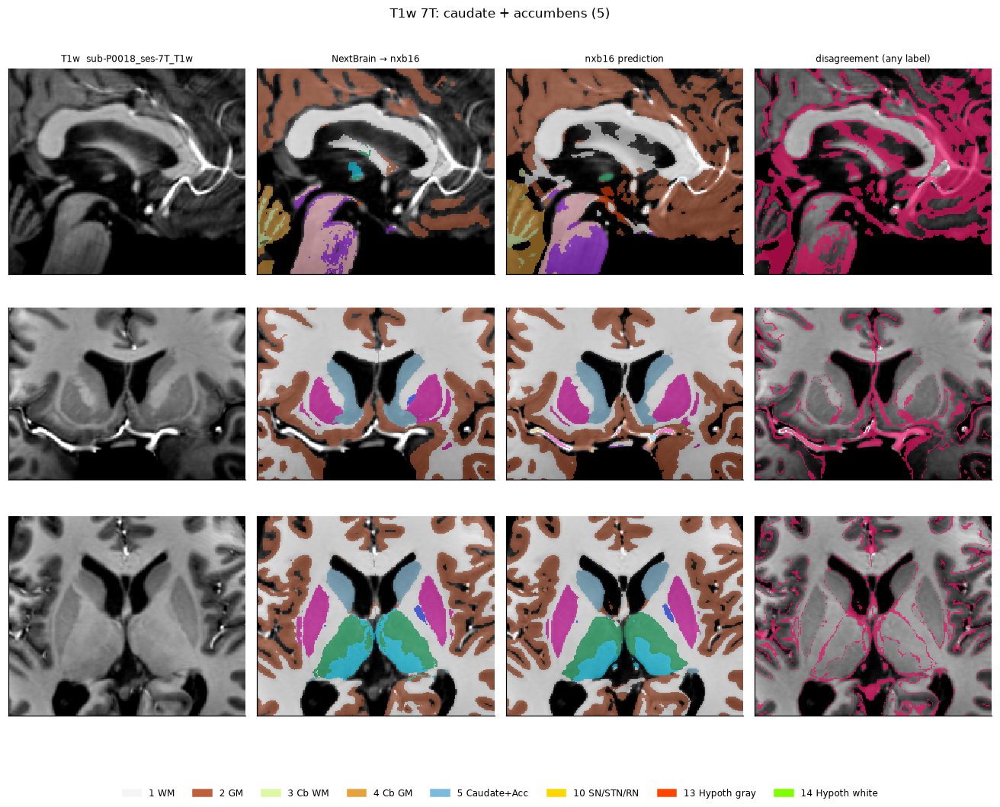

T1w 7T: nxb16 caudate outside NextBrain caudate: 1.36 mL


,nextbrain_label,name,mL,share_%
0,0,Unknown,0.98,72.1
1,7,white_matter_of_forebrain,0.33,24.5
2,79,putamen,0.01,1.0
3,117,bed_nucleus_of_stria_terminalis,0.01,0.8


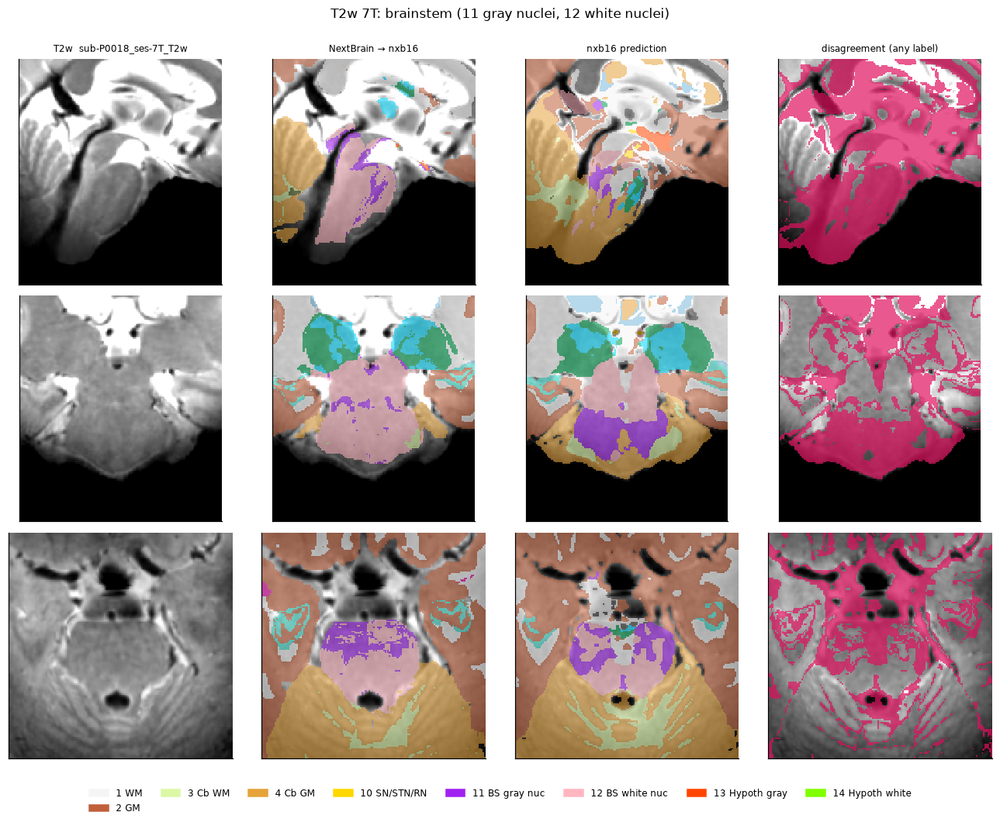

T2w 7T: NextBrain 12 → nxb16 11: 5.02 mL


,nextbrain_label,name,mL,share_%
0,580,pons,3.45,68.8
1,611,white_matter_of_hindbrain,1.37,27.2
2,384,midbrain_(mesencephalon),0.20,4.0
3,697,inferior_cerebellar_peduncle,0.00,0.0


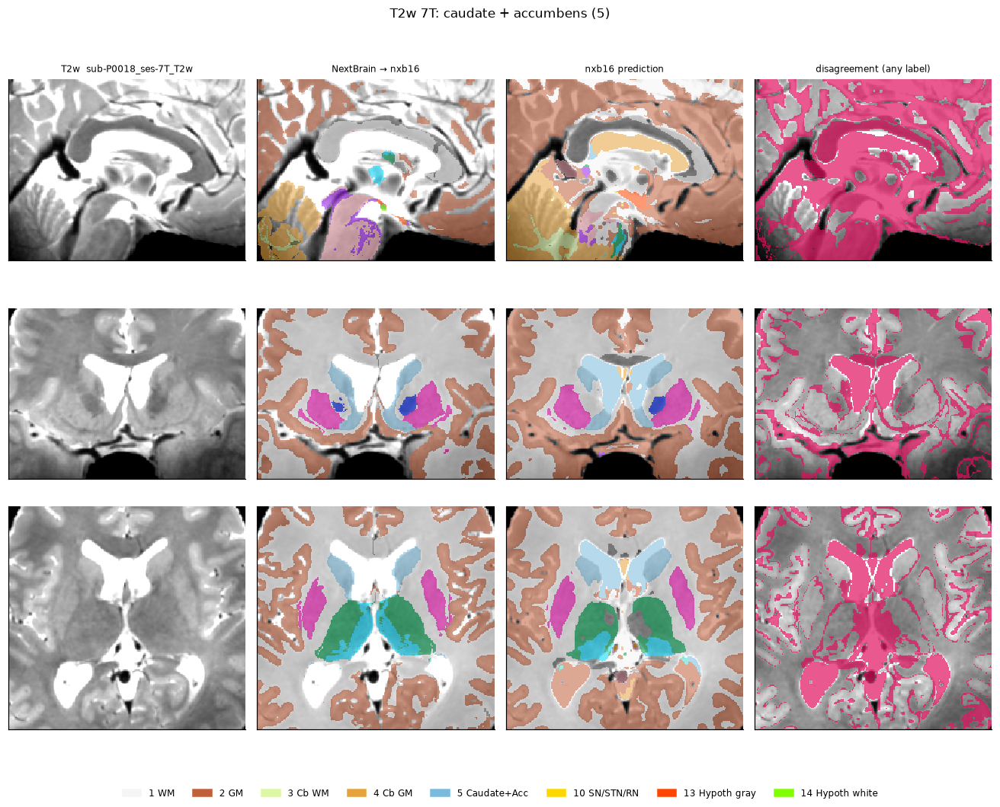

T2w 7T: nxb16 caudate outside NextBrain caudate: 21.53 mL


,nextbrain_label,name,mL,share_%
0,0,Unknown,20.39,94.7
1,7,white_matter_of_forebrain,0.92,4.3
2,354,alveus,0.05,0.2
3,117,bed_nucleus_of_stria_terminalis,0.03,0.1


In [18]:
for c in ["T1w", "T2w"]:
    d = REP7_CASES[c]
    zoom_fig(d, [11, 12], f"{c} 7T: brainstem (11 gray nuclei, 12 white nuclei)")
    sel = (d["gt"] == 12) & (d["pred"] == 11)
    print(f"{c} 7T: NextBrain 12 → nxb16 11: {sel.sum() * np.prod(d['zooms']) / 1000:.2f} mL")
    display(raw_breakdown(d, sel, top=4))
    zoom_fig(d, [5], f"{c} 7T: caudate + accumbens (5)", margin=15)
    sel = (d["pred"] == 5) & (d["gt"] != 5)
    print(f"{c} 7T: nxb16 caudate outside NextBrain caudate: {sel.sum() * np.prod(d['zooms']) / 1000:.2f} mL")
    display(raw_breakdown(d, sel, top=4))

,case,dice,abs_rel_vol_diff_pct
947,sub-R0821_ses-7T_T2w,0.289,54.732
886,sub-R0757_ses-7T_T2w,0.358,63.920
916,sub-R0789_ses-7T_T2w,0.386,58.060


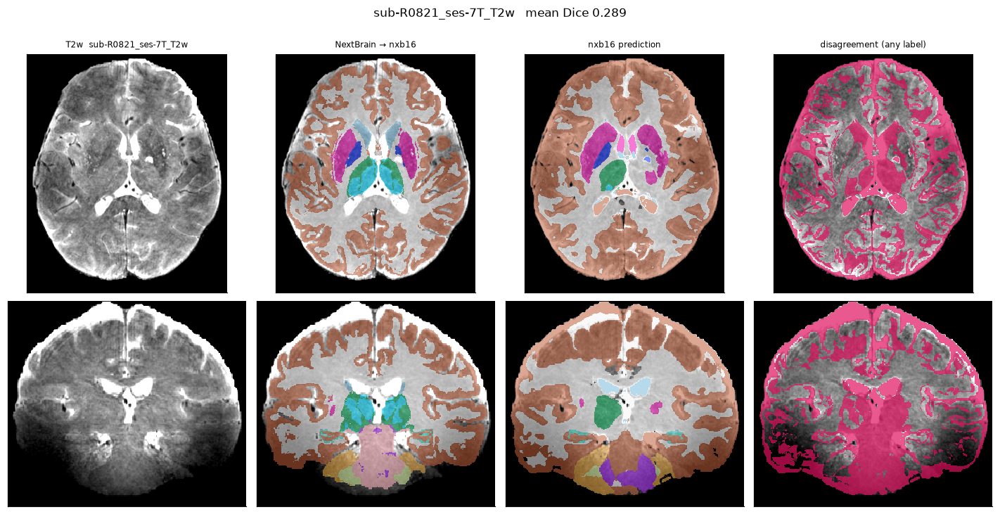

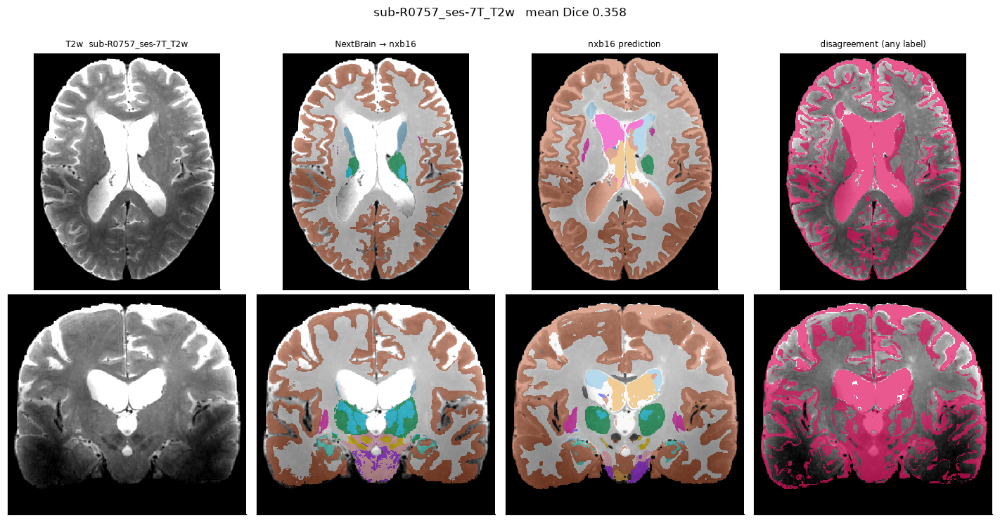

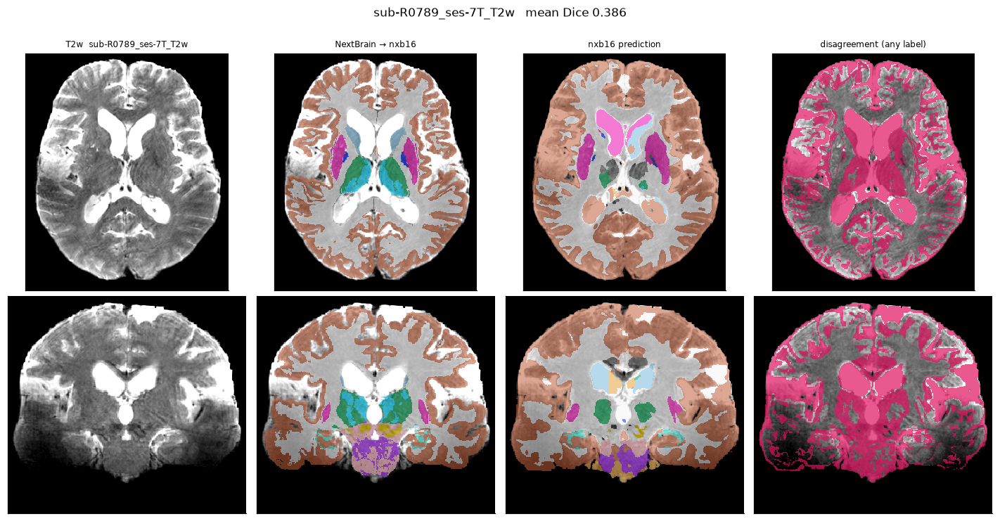

In [19]:
worst7 = q7[q7.contrast == "T2w"].nsmallest(3, "dice")
display(worst7[["case", "dice", "abs_rel_vol_diff_pct"]].round(3))
for case in worst7.case:
    sub = case.split("_")[0]
    for c in ["T2w", "T1w"]:
        cc = f"{sub}_ses-7T_{c}"
        if not (PRED / c / "7T" / f"{cc}.nii.gz").exists(): continue
        d = load_case(c, cc); cen = centroid(d["gt"] > 0)
        dc = q7[(q7.contrast == c) & (q7.case == cc)].dice.iloc[0]
        fig, axs = plt.subplots(2, 4, figsize=(13, 6.8))
        for row, axis in enumerate((2, 1)):
            show_row(axs[row], d, axis, cen[axis], box=crop_box(d["gt"] > 0, axis, 5, d["zooms"]), title=(row == 0))
        fig.suptitle(f"{cc}   mean Dice {dc:.3f}", y=1.0); plt.tight_layout(); plt.show()

**What we see (7T).** The same patterns as at 3T, on the same subject (`sub-P0018`):
- All extra tissue is again NextBrain label 0: a rim along the pial surface on T1w/FLAIR, plus, on **T2w, the
  lateral ventricles filled with tissue labels** (~21 mL of "caudate" outside NextBrain caudate, 95 % of it NextBrain label 0, same as 3T).
- Brainstem: ~5 mL of NextBrain `pons` / hindbrain white matter → nxb16 gray brainstem nuclei, same as at 3T.
- Worst 7T T2w cases: `sub-R0757` (and `sub-R0789`) have **enlarged ventricles** filled with tissue labels, the same failure
  as at 3T. `sub-R0821` is a **different failure: image quality**. The lower part of the image is dark and the signal is
  uneven (typical 7T B1 inhomogeneity), and nxb16 loses the brainstem/thalamus and labels the bright rim at the
  top as cortex. Its T1w is segmented normally.